### PART 1: Dataset Loading & Preparation

Loaded the original clients and properties datasets using Pandas. Created separate copies for data preprocessing and analysis.

In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Get project path
current_path = Path.cwd()

if current_path.name == "notebooks":
    project_path = current_path.parent
else:
    project_path = current_path

# Load datasets
clients = pd.read_csv(project_path / "data" / "clients.csv")
properties = pd.read_csv(project_path / "data" / "properties.csv")

# Create working copies
clients_clean = clients.copy()
properties_clean = properties.copy()

# Clean Sale Price
properties_clean["sale_price"] = pd.to_numeric(
    properties_clean["sale_price"]
    .astype(str)
    .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

# Convert Transaction Date
properties_clean["transaction_date"] = pd.to_datetime(
    properties_clean["transaction_date"],
    errors="coerce",
    dayfirst=True
)

# Display dataset information
print("DATA PREPROCESSING - DATASET PREPARATION")
print("----------------------------------------")

print("Clients Dataset Shape:", clients_clean.shape)
print("Properties Dataset Shape:", properties_clean.shape)

print("\nClients Dataset:")
display(clients_clean.head())

print("\nProperties Dataset:")
display(properties_clean.head())

print("\nDATASET PREPARATION COMPLETED!")

DATA PREPROCESSING - DATASET PREPARATION
----------------------------------------
Clients Dataset Shape: (2000, 12)
Properties Dataset Shape: (10000, 9)

Clients Dataset:


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,Yes,Website
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website



Properties Dataset:


,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref
0,1012,1,2024-01-01,Apartment,12,1160.36,300385.62,Sold,C0027
1,1015,1,2024-01-01,Apartment,15,782.25,208930.81,Sold,C0097
2,1021,1,2024-01-01,Apartment,21,756.21,218585.92,Sold,C0113
3,1030,1,2024-01-01,Apartment,30,743.09,246172.68,Sold,C0141
4,2016,2,2024-01-01,Apartment,16,701.66,212265.67,Sold,C0146



DATASET PREPARATION COMPLETED!


### PART 2: Missing Values Handling


Identified missing values in both datasets. Found 2,695 missing values in the properties dataset, mainly in the client_ref column.

In [3]:

print("MISSING VALUES ANALYSIS")
print("-----------------------")

# Check Clients Missing Values
print("\n1. CLIENTS DATASET")
print(clients_clean.isnull().sum())

# Check Properties Missing Values
print("\n2. PROPERTIES DATASET")
print(properties_clean.isnull().sum())

# Calculate total missing values
clients_missing = clients_clean.isnull().sum().sum()
properties_missing = properties_clean.isnull().sum().sum()

print("\n3. TOTAL MISSING VALUES")
print("Clients Missing Values:", clients_missing)
print("Properties Missing Values:", properties_missing)

# Check missing client references
print("\n4. MISSING CLIENT REFERENCES")
print(
    "Missing client_ref:",
    properties_clean["client_ref"].isnull().sum()
)

# Create missing reference indicator
properties_clean["client_ref_missing"] = (
    properties_clean["client_ref"].isnull()
)

print("\nMISSING VALUES ANALYSIS COMPLETED!")

MISSING VALUES ANALYSIS
-----------------------

1. CLIENTS DATASET
client_id              0
client_type            0
first_name             0
last_name              0
date_of_birth          0
gender                 0
country                0
region                 0
acquisition_purpose    0
satisfaction_score     0
loan_applied           0
referral_channel       0
dtype: int64

2. PROPERTIES DATASET
listing_id               0
tower_number             0
transaction_date         0
unit_category            0
unit_number              0
floor_area_sqft          0
sale_price               0
listing_status           0
client_ref            2695
client_ref_missing       0
dtype: int64

3. TOTAL MISSING VALUES
Clients Missing Values: 0
Properties Missing Values: 2695

4. MISSING CLIENT REFERENCES
Missing client_ref: 2695

MISSING VALUES ANALYSIS COMPLETED!


### PART 3: Categorical Data Analysis



Analyzed categorical features such as client type, gender, country, region, acquisition purpose, loan status and referral channel.


In [4]:

categorical_columns = [
    "client_type",
    "gender",
    "country",
    "region",
    "acquisition_purpose",
    "loan_applied",
    "referral_channel"
]

print("CATEGORICAL DATA ANALYSIS")
print("-------------------------")

for column in categorical_columns:
    print(f"\n{column.upper()}")
    print(clients_clean[column].value_counts())
    print("Unique Values:", clients_clean[column].nunique())

print("\nCATEGORICAL DATA ANALYSIS COMPLETED!")

CATEGORICAL DATA ANALYSIS
-------------------------

CLIENT_TYPE
client_type
Individual    1897
Company        103
Name: count, dtype: int64
Unique Values: 2

GENDER
gender
M    1012
F     988
Name: count, dtype: int64
Unique Values: 2

COUNTRY
country
USA          1538
UK             95
Canada         85
Germany        56
France         53
Belgium        43
Mexico         40
Australia      39
Russia         36
Denmark        15
Name: count, dtype: int64
Unique Values: 10

REGION
region
California                633
Nevada                    143
Colorado                  118
Arizona                   108
Oregon                     96
Utah                       87
Washington                 73
Virginia                   65
Texas                      56
Florida                    50
New York                   49
Georgia                    34
England                    29
Alberta                    27
Scotland                   25
Northern Ireland           24
Ohio                       2

### PART 4: Categorical Data Encoding


Converted categorical values into numerical format using Label Encoding and One-Hot Encoding. Prepared the data for machine learning algorithms.

In [5]:
from sklearn.preprocessing import LabelEncoder

# Create a copy of clients dataset
clients_encoded = clients_clean.copy()

print("CATEGORICAL DATA ENCODING")
print("-------------------------")

# Label Encoding for binary columns
label_columns = [
    "client_type",
    "gender",
    "acquisition_purpose",
    "loan_applied"
]

label_encoders = {}

for column in label_columns:
    encoder = LabelEncoder()
    clients_encoded[column] = encoder.fit_transform(
        clients_encoded[column].astype(str)
    )
    label_encoders[column] = encoder

# One-Hot Encoding for multiple category columns
onehot_columns = [
    "country",
    "region",
    "referral_channel"
]

clients_encoded = pd.get_dummies(
    clients_encoded,
    columns=onehot_columns,
    dtype=int
)

print("\nENCODED DATASET SHAPE:")
print(clients_encoded.shape)

print("\nENCODED DATASET PREVIEW:")
display(clients_encoded.head())

print("\nCATEGORICAL ENCODING COMPLETED!")

CATEGORICAL DATA ENCODING
-------------------------

ENCODED DATASET SHAPE:
(2000, 79)

ENCODED DATASET PREVIEW:


,client_id,client_type,first_name,last_name,date_of_birth,gender,acquisition_purpose,satisfaction_score,loan_applied,country_Australia,...,region_Virginia,region_Wales,region_Wallonia,region_Washington,region_Western Australia,region_Wyoming,region_Zealand,referral_channel_Agency,referral_channel_Client,referral_channel_Website
0,C0001,1,Kareem,Liu,05-11-1968,0,0,4,1,0,...,0,0,0,0,0,0,0,0,0,1
1,C0002,1,Trystan,Oconnor,11/26/1962,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1
2,C0003,1,Kale,Gay,04-07-1959,1,0,4,1,0,...,0,0,0,0,0,0,0,1,0,0
3,C0004,1,Russell,Gross,11/25/1959,1,0,5,0,0,...,0,0,0,0,0,0,0,0,0,1
4,C0005,0,Marleez,Co,2/28/1976,1,1,5,0,0,...,0,0,0,0,0,0,0,0,0,1



CATEGORICAL ENCODING COMPLETED!


### PART 5: Feature Selection


Selected relevant buyer features for clustering analysis. Removed unnecessary columns such as client ID, first name and last name from the model features.

In [6]:

print("FEATURE SELECTION")
print("-----------------")

# Create a working copy
model_data = clients_encoded.copy()

# Convert Date of Birth into datetime
dob = pd.to_datetime(
    clients_clean["date_of_birth"],
    errors="coerce",
    dayfirst=True
)

# Calculate buyer age
reference_date = pd.Timestamp.today().normalize()

model_data["age"] = (
    reference_date.year
    - dob.dt.year
    - (
        (reference_date.month < dob.dt.month)
        | (
            (reference_date.month == dob.dt.month)
            & (reference_date.day < dob.dt.day)
        )
    ).astype(int)
)

# Remove unnecessary columns
columns_to_drop = [
    "client_id",
    "first_name",
    "last_name",
    "date_of_birth"
]

model_data = model_data.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Select numerical features
selected_features = model_data.select_dtypes(
    include=["number"]
).copy()

print("\nSELECTED FEATURES:")
print(selected_features.columns.tolist())

print("\nSELECTED DATASET SHAPE:")
print(selected_features.shape)

print("\nMISSING VALUES IN SELECTED FEATURES:")
print(selected_features.isnull().sum())

print("\nFEATURE SELECTION COMPLETED!")

FEATURE SELECTION
-----------------

SELECTED FEATURES:
['client_type', 'gender', 'acquisition_purpose', 'satisfaction_score', 'loan_applied', 'country_Australia', 'country_Belgium', 'country_Canada', 'country_Denmark', 'country_France', 'country_Germany', 'country_Mexico', 'country_Russia', 'country_UK', 'country_USA', 'region_Alberta', 'region_Arizona', 'region_Baja California', 'region_Bavaria', 'region_Berlin', 'region_British Columbia', 'region_Brittany', 'region_Brussels', 'region_California', 'region_Capital Region', 'region_Central Denmark', 'region_Colorado', 'region_England', 'region_Flanders', 'region_Florida', 'region_Georgia', 'region_Hamburg', 'region_Hesse', 'region_Ile-de-France', 'region_Jalisco', 'region_Kansas', 'region_Krasnodar Krai', 'region_Manitoba', 'region_Mexico City', 'region_Moscow Oblast', 'region_Nevada', 'region_New South Wales', 'region_New York', 'region_Normandy', 'region_North Denmark', 'region_North Rhine-Westphalia', 'region_Northern Ireland', 'reg

### PART 6: Missing Values Imputation

Handled missing numerical feature values using SimpleImputer with median strategy. Ensured the selected dataset had no missing values.

In [7]:

from sklearn.impute import SimpleImputer

print("MISSING VALUES IMPUTATION")
print("-------------------------")

# Check missing values before imputation
print("\nBefore Imputation:")
print(selected_features.isnull().sum())

# Create median imputer
imputer = SimpleImputer(strategy="median")

# Fill missing values using median
imputed_array = imputer.fit_transform(selected_features)

# Convert back to DataFrame
selected_features = pd.DataFrame(
    imputed_array,
    columns=selected_features.columns,
    index=selected_features.index
)

# Check missing values after imputation
print("\nAfter Imputation:")
print(selected_features.isnull().sum())

print("\nFinal Dataset Shape:")
print(selected_features.shape)

print("\nMISSING VALUES IMPUTATION COMPLETED!")

MISSING VALUES IMPUTATION
-------------------------

Before Imputation:
client_type                    0
gender                         0
acquisition_purpose            0
satisfaction_score             0
loan_applied                   0
                            ... 
region_Zealand                 0
referral_channel_Agency        0
referral_channel_Client        0
referral_channel_Website       0
age                         1145
Length: 76, dtype: int64

After Imputation:
client_type                 0
gender                      0
acquisition_purpose         0
satisfaction_score          0
loan_applied                0
                           ..
region_Zealand              0
referral_channel_Agency     0
referral_channel_Client     0
referral_channel_Website    0
age                         0
Length: 76, dtype: int64

Final Dataset Shape:
(2000, 76)

MISSING VALUES IMPUTATION COMPLETED!


### PART 7: Feature Scaling


Applied StandardScaler to standardize numerical features. Converted the selected features into a common scale for better clustering performance.

In [8]:

from sklearn.preprocessing import StandardScaler

print("FEATURE SCALING")
print("----------------")

# Create StandardScaler object
scaler = StandardScaler()

# Apply feature scaling
scaled_array = scaler.fit_transform(selected_features)

# Convert scaled data into DataFrame
scaled_features = pd.DataFrame(
    scaled_array,
    columns=selected_features.columns,
    index=selected_features.index
)

# Display scaled dataset
print("\nSCALED DATASET PREVIEW:")
display(scaled_features.head())

# Check mean and standard deviation
print("\nFEATURE MEAN:")
print(scaled_features.mean().round(2))

print("\nFEATURE STANDARD DEVIATION:")
print(scaled_features.std().round(2))

print("\nSCALED DATASET SHAPE:")
print(scaled_features.shape)

print("\nFEATURE SCALING COMPLETED!")

FEATURE SCALING
----------------

SCALED DATASET PREVIEW:


,client_type,gender,acquisition_purpose,satisfaction_score,loan_applied,country_Australia,country_Belgium,country_Canada,country_Denmark,country_France,...,region_Wales,region_Wallonia,region_Washington,region_Western Australia,region_Wyoming,region_Zealand,referral_channel_Agency,referral_channel_Client,referral_channel_Website,age
0,0.233016,-1.012073,-0.666366,0.687089,1.310493,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.207898
1,0.233016,0.988071,-0.666366,-1.435740,-0.763072,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.030131
2,0.233016,0.988071,-0.666366,0.687089,1.310493,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,1.355315,-0.325875,-1.108898,1.007849
3,0.233016,0.988071,-0.666366,1.394698,-0.763072,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.030131
4,-4.291559,0.988071,1.500677,1.394698,-0.763072,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.030131



FEATURE MEAN:
client_type                -0.0
gender                      0.0
acquisition_purpose        -0.0
satisfaction_score          0.0
loan_applied                0.0
                           ... 
region_Zealand             -0.0
referral_channel_Agency    -0.0
referral_channel_Client    -0.0
referral_channel_Website    0.0
age                        -0.0
Length: 76, dtype: float64

FEATURE STANDARD DEVIATION:
client_type                 1.0
gender                      1.0
acquisition_purpose         1.0
satisfaction_score          1.0
loan_applied                1.0
                           ... 
region_Zealand              1.0
referral_channel_Agency     1.0
referral_channel_Client     1.0
referral_channel_Website    1.0
age                         1.0
Length: 76, dtype: float64

SCALED DATASET SHAPE:
(2000, 76)

FEATURE SCALING COMPLETED!


### PART 8: Preprocessed Dataset Validation

Checked dataset shape, missing values, duplicate records and infinite values. Confirmed that the preprocessed dataset was suitable for clustering.

In [9]:

print("PREPROCESSED DATASET VALIDATION")
print("--------------------------------")

# Check dataset shape
print("\n1. DATASET SHAPE")
print(scaled_features.shape)

# Check missing values
print("\n2. MISSING VALUES")
print(scaled_features.isnull().sum().sum())

# Check duplicate records
print("\n3. DUPLICATE RECORDS")
print(scaled_features.duplicated().sum())

# Check infinite values
print("\n4. INFINITE VALUES")
print(np.isinf(scaled_features.to_numpy()).sum())

# Check data types
print("\n5. DATA TYPES")
print(scaled_features.dtypes.value_counts())

# Display final dataset
print("\n6. FINAL DATASET PREVIEW")
display(scaled_features.head())

print("\nPREPROCESSING VALIDATION COMPLETED!")

PREPROCESSED DATASET VALIDATION
--------------------------------

1. DATASET SHAPE
(2000, 76)

2. MISSING VALUES
0

3. DUPLICATE RECORDS
402

4. INFINITE VALUES
0

5. DATA TYPES
float64    76
Name: count, dtype: int64

6. FINAL DATASET PREVIEW


,client_type,gender,acquisition_purpose,satisfaction_score,loan_applied,country_Australia,country_Belgium,country_Canada,country_Denmark,country_France,...,region_Wales,region_Wallonia,region_Washington,region_Western Australia,region_Wyoming,region_Zealand,referral_channel_Agency,referral_channel_Client,referral_channel_Website,age
0,0.233016,-1.012073,-0.666366,0.687089,1.310493,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.207898
1,0.233016,0.988071,-0.666366,-1.435740,-0.763072,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.030131
2,0.233016,0.988071,-0.666366,0.687089,1.310493,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,1.355315,-0.325875,-1.108898,1.007849
3,0.233016,0.988071,-0.666366,1.394698,-0.763072,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.030131
4,-4.291559,0.988071,1.500677,1.394698,-0.763072,-0.141024,-0.148231,-0.210681,-0.086929,-0.164989,...,-0.09259,-0.086929,-0.194635,-0.054855,-0.022366,-0.031639,-0.737836,-0.325875,0.901796,0.030131



PREPROCESSING VALIDATION COMPLETED!


#### PART 8.1: Duplicate Records Investigation


In [10]:
# PART 8.1: DUPLICATE RECORDS INVESTIGATION

print("DUPLICATE RECORDS INVESTIGATION")
print("--------------------------------")

# Identify duplicate feature rows
duplicate_mask = scaled_features.duplicated(keep=False)

# Count duplicate rows
print("Duplicate Feature Rows:",
      duplicate_mask.sum())

# Display corresponding original client records
print("\nORIGINAL CLIENT RECORDS:")
display(
    clients_clean.loc[duplicate_mask].head(10)
)

# Check original client IDs
print("\nORIGINAL CLIENT IDs:")
print(
    clients_clean.loc[duplicate_mask, "client_id"].head(10)
)

print("\nINVESTIGATION COMPLETED!")

DUPLICATE RECORDS INVESTIGATION
--------------------------------
Duplicate Feature Rows: 589

ORIGINAL CLIENT RECORDS:


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website
7,C0008,Individual,Kayden,Olsen,10/17/1969,F,USA,California,Home,5,No,Website
9,C0010,Individual,Nicolas,Navarro,6/17/1966,M,USA,Oregon,Investment,3,No,Agency
10,C0011,Individual,Laci,Guerra,6/17/1956,F,USA,California,Home,2,Yes,Website
11,C0012,Company,Kylax,Co,4/25/1975,M,USA,California,Investment,5,No,Website
14,C0015,Individual,Jaylynn,Hickman,8/19/1941,F,USA,California,Home,5,No,Client
19,C0020,Individual,Camille,Sharp,10/17/1967,F,USA,California,Home,5,No,Website



ORIGINAL CLIENT IDs:
1     C0002
2     C0003
3     C0004
4     C0005
7     C0008
9     C0010
10    C0011
11    C0012
14    C0015
19    C0020
Name: client_id, dtype: str

INVESTIGATION COMPLETED!


### PART 9: Save Preprocessed Dataset


Saved the scaled features and client IDs as CSV files. These files were used as input for clustering models.


In [11]:

print("SAVING PREPROCESSED DATASET")
print("---------------------------")

# Create processed data folder
processed_path = project_path / "data" / "processed"
processed_path.mkdir(parents=True, exist_ok=True)

# Save scaled features
scaled_features.to_csv(
    processed_path / "scaled_features.csv",
    index=False
)

# Save original client IDs separately
clients_clean[["client_id"]].to_csv(
    processed_path / "client_ids.csv",
    index=False
)

print("Scaled Features Shape:", scaled_features.shape)

print("\nFiles Saved Successfully:")
print("1. scaled_features.csv")
print("2. client_ids.csv")

print("\nPREPROCESSED DATASET SAVED SUCCESSFULLY!")

SAVING PREPROCESSED DATASET
---------------------------
Scaled Features Shape: (2000, 76)

Files Saved Successfully:
1. scaled_features.csv
2. client_ids.csv

PREPROCESSED DATASET SAVED SUCCESSFULLY!


### PART 10: K-Means Clustering Model

Applied K-Means clustering with different cluster numbers from 2 to 10. Evaluated the models using inertia and silhouette scores.

In [12]:

import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("K-MEANS CLUSTERING MODEL")
print("------------------------")

# Load preprocessed features
scaled_features = pd.read_csv(
    project_path / "data" / "processed" / "scaled_features.csv"
)

print("Dataset Shape:", scaled_features.shape)
print("\nDataset Loaded Successfully!")

K-MEANS CLUSTERING MODEL
------------------------
Dataset Shape: (2000, 76)

Dataset Loaded Successfully!


In [13]:
# Test different numbers of clusters

inertia_values = []
silhouette_values = []

cluster_range = range(2, 11)

for k in cluster_range:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(scaled_features)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        scaled_features,
        cluster_labels
    )

    silhouette_values.append(score)

    print(
        f"Clusters: {k} | "
        f"Inertia: {kmeans.inertia_:.2f} | "
        f"Silhouette Score: {score:.4f}"
    )

Clusters: 2 | Inertia: 148329.27 | Silhouette Score: 0.0481
Clusters: 3 | Inertia: 143735.13 | Silhouette Score: 0.3824
Clusters: 4 | Inertia: 141738.79 | Silhouette Score: 0.4055
Clusters: 5 | Inertia: 141098.09 | Silhouette Score: -0.0307
Clusters: 6 | Inertia: 137486.45 | Silhouette Score: 0.0575
Clusters: 7 | Inertia: 133883.12 | Silhouette Score: 0.0432
Clusters: 8 | Inertia: 131330.54 | Silhouette Score: 0.0534
Clusters: 9 | Inertia: 128628.63 | Silhouette Score: 0.0720
Clusters: 10 | Inertia: 127150.11 | Silhouette Score: 0.1015


In [14]:
# Create clustering evaluation table

clustering_results = pd.DataFrame({
    "Number of Clusters": list(cluster_range),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(clustering_results)

,Number of Clusters,Inertia,Silhouette Score
0,2,148329.271929,0.048142
1,3,143735.129547,0.382447
2,4,141738.793787,0.405489
3,5,141098.091400,-0.030685
4,6,137486.449309,0.057522
5,7,133883.120069,0.043245
6,8,131330.543581,0.053411
7,9,128628.634122,0.071967
8,10,127150.113566,0.101528


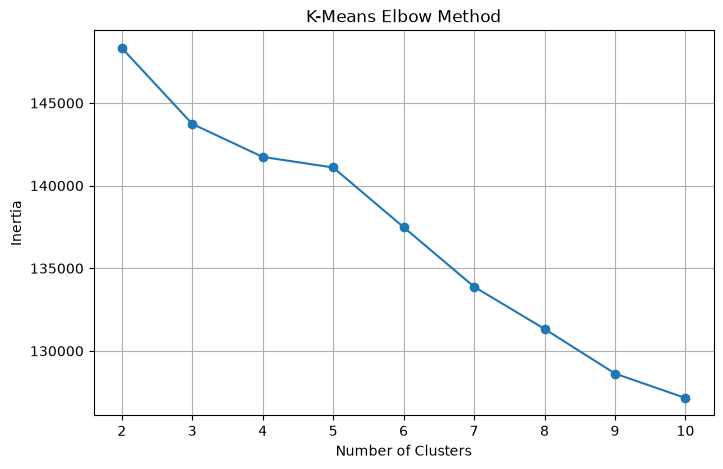

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    list(cluster_range),
    inertia_values,
    marker="o"
)

plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(cluster_range))
plt.grid(True)

plt.show()

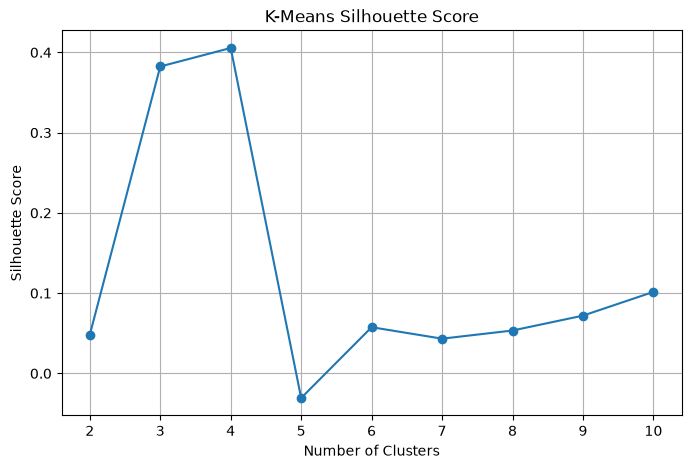

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(cluster_range),
    silhouette_values,
    marker="o"
)

plt.title("K-Means Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(cluster_range))
plt.grid(True)

plt.show()

### PART 11: Final K-Means Clustering Model


Selected four clusters based on the silhouette score and trained the final K-Means model. Saved the buyer cluster assignments.

In [53]:
# STEP 1 : FINAL K-MEANS CLUSTERING

print("FINAL K-MEANS CLUSTERING")
print("------------------------")

best_k = int(
    clustering_results.loc[
        clustering_results["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Selected Number of Clusters:", best_k)

# STEP 2: TRAIN FINAL K-MEANS MODEL

kmeans_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(
    scaled_features
)

print("FINAL K-MEANS MODEL TRAINED SUCCESSFULLY!")
print("Number of Clusters:", best_k)
print("Total Buyers:", len(cluster_labels))

# STEP 3: ADD CLUSTER LABELS TO BUYER IDS

client_ids = pd.read_csv(
    project_path / "data" / "processed" / "client_ids.csv"
)

cluster_results = client_ids.copy()

cluster_results["cluster"] = cluster_labels

print("BUYER CLUSTER RESULTS")
print("---------------------")

display(cluster_results.head(10))

# STEP 4: BUYER SEGMENT DISTRIBUTION

cluster_counts = (
    cluster_results["cluster"]
    .value_counts()
    .sort_index()
)

print("BUYER SEGMENT DISTRIBUTION")
print("--------------------------")

display(cluster_counts)

print("\nTotal Buyers:", cluster_counts.sum())
print("Total Clusters:", len(cluster_counts))

FINAL K-MEANS CLUSTERING
------------------------
Selected Number of Clusters: 4
FINAL K-MEANS MODEL TRAINED SUCCESSFULLY!
Number of Clusters: 4
Total Buyers: 2000
BUYER CLUSTER RESULTS
---------------------


,client_id,cluster
0,C0001,1
1,C0002,1
2,C0003,1
3,C0004,1
4,C0005,1
5,C0006,1
6,C0007,1
7,C0008,1
8,C0009,1
9,C0010,1


BUYER SEGMENT DISTRIBUTION
--------------------------


cluster
0     356
1    1623
2      10
3      11
Name: count, dtype: int64


Total Buyers: 2000
Total Clusters: 4


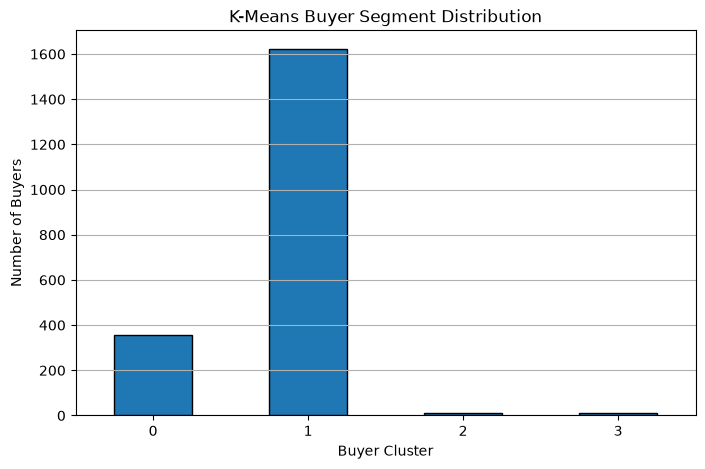

K-MEANS RESULTS SAVED SUCCESSFULLY!
File: kmeans_cluster_results.csv
Total Buyers: 2000
Total Clusters: 4


In [54]:
# STEP 5: BUYER SEGMENT VISUALIZATION

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

cluster_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("K-Means Buyer Segment Distribution")
plt.xlabel("Buyer Cluster")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()
# STEP 6: SAVE K-MEANS CLUSTERING RESULTS

results_path = project_path / "data" / "processed"

cluster_results.to_csv(
    results_path / "kmeans_cluster_results.csv",
    index=False
)

print("K-MEANS RESULTS SAVED SUCCESSFULLY!")
print("File: kmeans_cluster_results.csv")
print("Total Buyers:", len(cluster_results))
print("Total Clusters:", cluster_results["cluster"].nunique())

### PART 12: Buyer Segment Analysis

Analyzed buyer segments based on client type, acquisition purpose, loan status, gender and customer satisfaction. Studied the characteristics of each cluster.

In [23]:
# STEP 1: BUYER SEGMENT ANALYSIS

print("BUYER SEGMENT ANALYSIS")
print("----------------------")

# Merge cluster labels with original client data

clustered_clients = clients_clean.merge(
    cluster_results[["client_id", "cluster"]],
    on="client_id",
    how="left"
)

print("Clustered Dataset Shape:", clustered_clients.shape)

print("\nCluster Distribution:")
print(
    clustered_clients["cluster"]
    .value_counts()
    .sort_index()
)

BUYER SEGMENT ANALYSIS
----------------------
Clustered Dataset Shape: (2000, 13)

Cluster Distribution:
cluster
0     356
1    1623
2      10
3      11
Name: count, dtype: int64


In [24]:
# STEP 2: BUYER TYPE ANALYSIS

print("BUYER TYPE ANALYSIS")
print("--------------------")

buyer_type_profile = pd.crosstab(
    clustered_clients["cluster"],
    clustered_clients["client_type"],
    normalize="index"
) * 100

display(buyer_type_profile.round(2))

BUYER TYPE ANALYSIS
--------------------


client_type,Company,Individual
cluster,,
0,5.06,94.94
1,5.11,94.89
2,0.00,100.00
3,18.18,81.82


In [27]:
# STEP 3: ACQUISITION PURPOSE ANALYSIS

print("ACQUISITION PURPOSE ANALYSIS")
print("----------------------------")

purpose_profile = pd.crosstab(
    clustered_clients["cluster"],
    clustered_clients["acquisition_purpose"],
    normalize="index"
) * 100

display(purpose_profile.round(2))

# STEP 4: LOAN APPLICATION ANALYSIS

print("LOAN APPLICATION ANALYSIS")
print("-------------------------")

loan_profile = pd.crosstab(
    clustered_clients["cluster"],
    clustered_clients["loan_applied"],
    normalize="index"
) * 100

display(loan_profile.round(2))



# STEP 5: GENDER DISTRIBUTION ANALYSIS

print("GENDER DISTRIBUTION")
print("-------------------")

gender_profile = pd.crosstab(
    clustered_clients["cluster"],
    clustered_clients["gender"],
    normalize="index"
) * 100

display(gender_profile.round(2))

ACQUISITION PURPOSE ANALYSIS
----------------------------


acquisition_purpose,Home,Investment
cluster,,
0,70.22,29.78
1,69.01,30.99
2,70.00,30.00
3,72.73,27.27


LOAN APPLICATION ANALYSIS
-------------------------


loan_applied,No,Yes
cluster,,
0,62.08,37.92
1,63.22,36.78
2,90.00,10.00
3,72.73,27.27


GENDER DISTRIBUTION
-------------------


gender,F,M
cluster,,
0,48.60,51.40
1,49.66,50.34
2,50.00,50.00
3,36.36,63.64


In [28]:
print("CUSTOMER SATISFACTION BY CLUSTER")
print("--------------------------------")

satisfaction_profile = clustered_clients.groupby("cluster")[
    "satisfaction_score"
].agg(["count", "mean", "min", "max"])

display(satisfaction_profile.round(2))




print("COUNTRY-WISE BUYER ANALYSIS")
print("---------------------------")

for cluster_number in sorted(
    clustered_clients["cluster"].dropna().unique()
):

    print(f"\nCLUSTER {int(cluster_number)}")

    country_counts = (
        clustered_clients[
            clustered_clients["cluster"] == cluster_number
        ]["country"]
        .value_counts()
        .head(5)
    )

    display(country_counts)




CUSTOMER SATISFACTION BY CLUSTER
--------------------------------


,count,mean,min,max
cluster,,,,
0,356,3.00,1,5
1,1623,3.04,1,5
2,10,2.00,1,4
3,11,3.27,1,5


COUNTRY-WISE BUYER ANALYSIS
---------------------------

CLUSTER 0


country
UK         95
France     53
Germany    45
Belgium    43
Mexico     40
Name: count, dtype: int64


CLUSTER 1


country
USA       1538
Canada      85
Name: count, dtype: int64


CLUSTER 2


country
Russia    10
Name: count, dtype: int64


CLUSTER 3


country
Germany    11
Name: count, dtype: int64

### PART 13: Hierarchical Clustering

Applied Agglomerative Hierarchical Clustering with different cluster numbers. Selected two clusters based on the highest silhouette score.

In [29]:
# Load Preprocessed Dataset
print("HIERARCHICAL CLUSTERING")
print("-----------------------")

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

scaled_features = pd.read_csv(
    project_path / "data" / "processed" / "scaled_features.csv"
)

print("Dataset Shape:", scaled_features.shape)
print("Dataset Loaded Successfully!")
# Evaluate Different Cluster Numbers
hierarchical_scores = []
cluster_range = range(2, 7)

for k in cluster_range:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(scaled_features)

    score = silhouette_score(scaled_features, labels)
    hierarchical_scores.append(score)

    print(
        f"Clusters: {k} | "
        f"Silhouette Score: {score:.4f}"
    )


# Display Evaluation Results
hierarchical_results = pd.DataFrame({
    "Number of Clusters": list(cluster_range),
    "Silhouette Score": hierarchical_scores
})

display(hierarchical_results)



best_hierarchical_k = int(
    hierarchical_results.loc[
        hierarchical_results["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Best Hierarchical Clusters:", best_hierarchical_k)

HIERARCHICAL CLUSTERING
-----------------------
Dataset Shape: (2000, 76)
Dataset Loaded Successfully!
Clusters: 2 | Silhouette Score: 0.3779
Clusters: 3 | Silhouette Score: 0.2934
Clusters: 4 | Silhouette Score: 0.3036
Clusters: 5 | Silhouette Score: 0.3088
Clusters: 6 | Silhouette Score: 0.3158


,Number of Clusters,Silhouette Score
0,2,0.377855
1,3,0.293418
2,4,0.303564
3,5,0.308792
4,6,0.315789


Best Hierarchical Clusters: 2


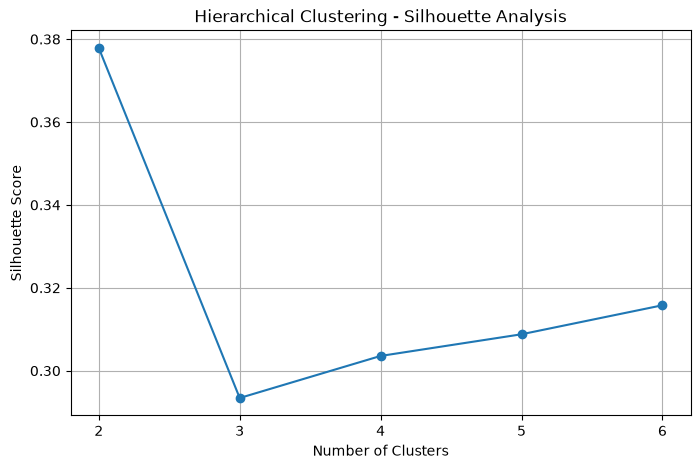

In [30]:
# Hierarchical Clustering Silhouette
plt.figure(figsize=(8, 5))

plt.plot(
    list(cluster_range),
    hierarchical_scores,
    marker="o"
)

plt.title("Hierarchical Clustering - Silhouette Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.show()

In [33]:
# Train Final Hierarchical Clustering Model and Create Cluster Results
hierarchical_model = AgglomerativeClustering(
    n_clusters=best_hierarchical_k,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(
    scaled_features
)

print("HIERARCHICAL MODEL TRAINED SUCCESSFULLY!")
print("Number of Clusters:", best_hierarchical_k)
print("Total Buyers:", len(hierarchical_labels))

client_ids = pd.read_csv(
    project_path / "data" / "processed" / "client_ids.csv"
)

hierarchical_results_final = client_ids.copy()

hierarchical_results_final["hierarchical_cluster"] = (
    hierarchical_labels
)

display(hierarchical_results_final.head(10))



hierarchical_counts = (
    hierarchical_results_final["hierarchical_cluster"]
    .value_counts()
    .sort_index()
)

print("BUYER DISTRIBUTION BY HIERARCHICAL CLUSTER")
print("------------------------------------------")

display(hierarchical_counts)

print("Total Buyers:", hierarchical_counts.sum())
print("Total Clusters:", len(hierarchical_counts))

HIERARCHICAL MODEL TRAINED SUCCESSFULLY!
Number of Clusters: 2
Total Buyers: 2000


,client_id,hierarchical_cluster
0,C0001,1
1,C0002,1
2,C0003,1
3,C0004,1
4,C0005,1
5,C0006,1
6,C0007,0
7,C0008,1
8,C0009,1
9,C0010,1


BUYER DISTRIBUTION BY HIERARCHICAL CLUSTER
------------------------------------------


hierarchical_cluster
0     462
1    1538
Name: count, dtype: int64

Total Buyers: 2000
Total Clusters: 2


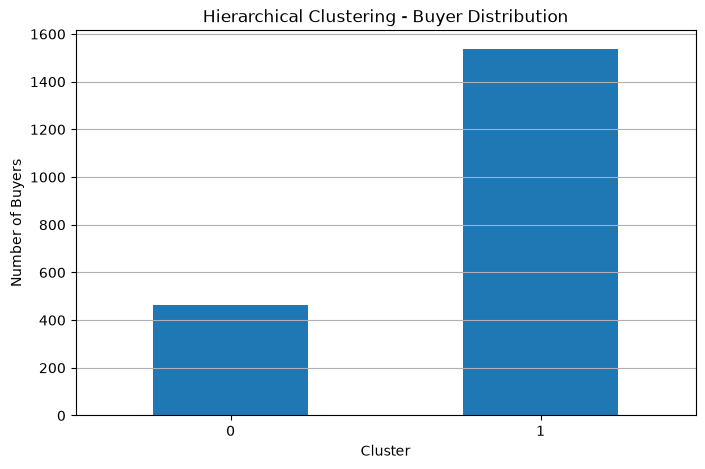

FINAL HIERARCHICAL SILHOUETTE SCORE
-----------------------------------
Silhouette Score: 0.3779


In [35]:
# Hierarchical Clustering - Buyer Distribution
plt.figure(figsize=(8, 5))

hierarchical_counts.plot(kind="bar")

plt.title("Hierarchical Clustering - Buyer Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()


final_hierarchical_score = silhouette_score(
    scaled_features,
    hierarchical_labels
)

print("FINAL HIERARCHICAL SILHOUETTE SCORE")
print("-----------------------------------")
print(f"Silhouette Score: {final_hierarchical_score:.4f}")

In [36]:
# Save Hierarchical Clustering Results and Validate Dataset
results_path = project_path / "data" / "processed"

hierarchical_results_final.to_csv(
    results_path / "hierarchical_cluster_results.csv",
    index=False
)

print("HIERARCHICAL RESULTS SAVED SUCCESSFULLY!")
print("File: hierarchical_cluster_results.csv")
print("Total Buyers:", len(hierarchical_results_final))


print("HIERARCHICAL CLUSTERING VALIDATION")
print("----------------------------------")

print(
    "Dataset Shape:",
    hierarchical_results_final.shape
)

print(
    "Missing Cluster Values:",
    hierarchical_results_final["hierarchical_cluster"].isnull().sum()
)

print(
    "Unique Clusters:",
    hierarchical_results_final["hierarchical_cluster"].nunique()
)

print(
    "Duplicate Client IDs:",
    hierarchical_results_final["client_id"].duplicated().sum()
)

HIERARCHICAL RESULTS SAVED SUCCESSFULLY!
File: hierarchical_cluster_results.csv
Total Buyers: 2000
HIERARCHICAL CLUSTERING VALIDATION
----------------------------------
Dataset Shape: (2000, 2)
Missing Cluster Values: 0
Unique Clusters: 2
Duplicate Client IDs: 0


### PART 14: K-Means vs Hierarchical Model Comparison

Compared K-Means and Hierarchical Clustering using silhouette scores. K-Means achieved 0.4055, while Hierarchical Clustering achieved 0.3779.

In [38]:
# step 1 : Load both clustering results
print("CLUSTERING MODEL COMPARISON")
print("---------------------------")

kmeans_results = pd.read_csv(
    project_path / "data" / "processed" / "kmeans_cluster_results.csv"
)

hierarchical_results = pd.read_csv(
    project_path / "data" / "processed" / "hierarchical_cluster_results.csv"
)

scaled_features = pd.read_csv(
    project_path / "data" / "processed" / "scaled_features.csv"
)

print("K-Means Shape:", kmeans_results.shape)
print("Hierarchical Shape:", hierarchical_results.shape)
print("Scaled Features Shape:", scaled_features.shape)

print("\nAll datasets loaded successfully!")

# Step 2: Validate client IDs

print("CLIENT ID VALIDATION")
print("--------------------")

print(
    "K-Means Duplicate IDs:",
    kmeans_results["client_id"].duplicated().sum()
)

print(
    "Hierarchical Duplicate IDs:",
    hierarchical_results["client_id"].duplicated().sum()
)

print(
    "Same Client IDs:",
    set(kmeans_results["client_id"]) ==
    set(hierarchical_results["client_id"])
)

# Step 3: Calculate K-Means Silhouette Score

kmeans_score = silhouette_score(
    scaled_features,
    kmeans_results["cluster"]
)

print("K-MEANS SILHOUETTE SCORE")
print("------------------------")
print(f"Silhouette Score: {kmeans_score:.4f}")

# Step 4: Calculate Hierarchical Silhouette Score

hierarchical_score = silhouette_score(
    scaled_features,
    hierarchical_results["hierarchical_cluster"]
)

print("HIERARCHICAL SILHOUETTE SCORE")
print("-----------------------------")
print(f"Silhouette Score: {hierarchical_score:.4f}")

# Step 5: Create model comparison table
comparison_results = pd.DataFrame({
    "Model": ["K-Means", "Hierarchical"],
    "Number of Clusters": [
        kmeans_results["cluster"].nunique(),
        hierarchical_results["hierarchical_cluster"].nunique()
    ],
    "Silhouette Score": [
        kmeans_score,
        hierarchical_score
    ]
})

display(comparison_results.round(4))

# Step 6: Identify the higher silhouette score

best_model = comparison_results.loc[
    comparison_results["Silhouette Score"].idxmax(),
    "Model"
]

print("MODEL WITH HIGHER SILHOUETTE SCORE")
print("----------------------------------")
print("Selected Model:", best_model)

CLUSTERING MODEL COMPARISON
---------------------------
K-Means Shape: (2000, 2)
Hierarchical Shape: (2000, 2)
Scaled Features Shape: (2000, 76)

All datasets loaded successfully!
CLIENT ID VALIDATION
--------------------
K-Means Duplicate IDs: 0
Hierarchical Duplicate IDs: 0
Same Client IDs: True
K-MEANS SILHOUETTE SCORE
------------------------
Silhouette Score: 0.4055
HIERARCHICAL SILHOUETTE SCORE
-----------------------------
Silhouette Score: 0.3779


,Model,Number of Clusters,Silhouette Score
0,K-Means,4,0.4055
1,Hierarchical,2,0.3779


MODEL WITH HIGHER SILHOUETTE SCORE
----------------------------------
Selected Model: K-Means


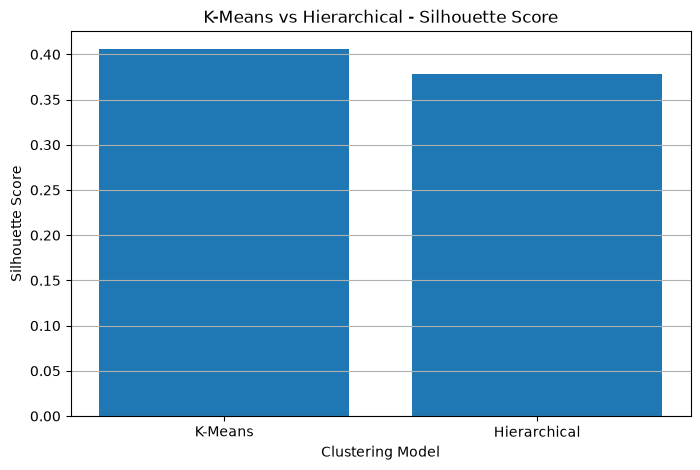

K-MEANS BUYER DISTRIBUTION
--------------------------


cluster
0     356
1    1623
2      10
3      11
Name: count, dtype: int64


HIERARCHICAL BUYER DISTRIBUTION
--------------------------------


hierarchical_cluster
0     462
1    1538
Name: count, dtype: int64

In [40]:
# Step 7: Visualize silhouette score comparison
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_results["Model"],
    comparison_results["Silhouette Score"]
)

plt.title("K-Means vs Hierarchical - Silhouette Score")
plt.xlabel("Clustering Model")
plt.ylabel("Silhouette Score")
plt.grid(axis="y")

plt.show()

# Step 8: Compare buyer distribution

print("K-MEANS BUYER DISTRIBUTION")
print("--------------------------")

kmeans_distribution = (
    kmeans_results["cluster"]
    .value_counts()
    .sort_index()
)

display(kmeans_distribution)

print("\nHIERARCHICAL BUYER DISTRIBUTION")
print("--------------------------------")

hierarchical_distribution = (
    hierarchical_results["hierarchical_cluster"]
    .value_counts()
    .sort_index()
)

display(hierarchical_distribution)

K-MEANS CLUSTER PERCENTAGES


cluster
0    17.80
1    81.15
2     0.50
3     0.55
Name: count, dtype: float64


HIERARCHICAL CLUSTER PERCENTAGES


hierarchical_cluster
0    23.1
1    76.9
Name: count, dtype: float64

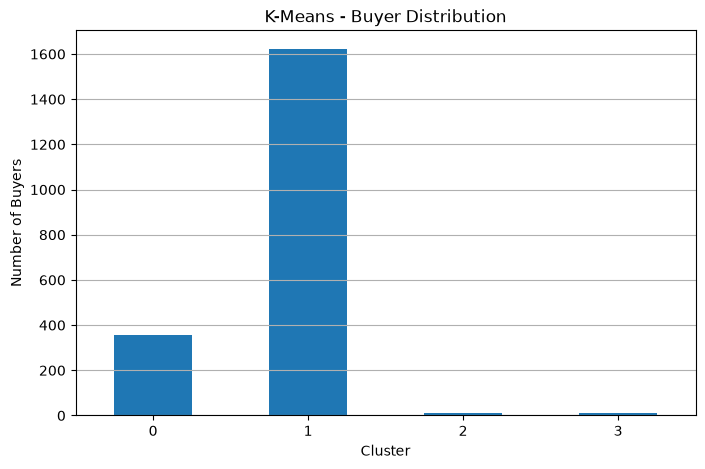

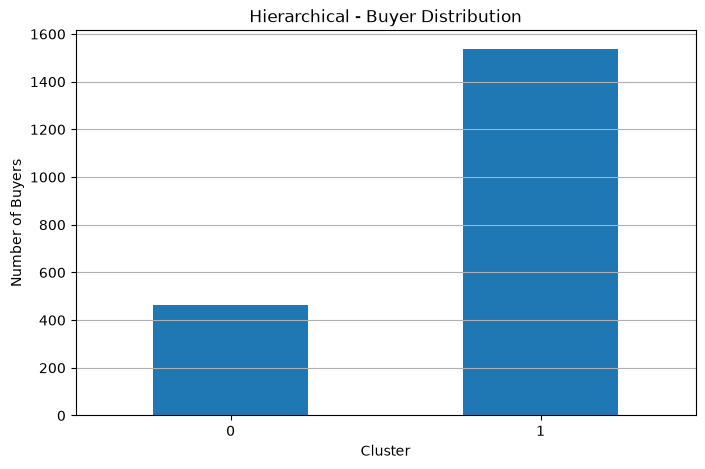

In [41]:
# Step 9: Calculate cluster percentages
kmeans_percentage = (
    kmeans_distribution / len(kmeans_results) * 100
)

hierarchical_percentage = (
    hierarchical_distribution / len(hierarchical_results) * 100
)

print("K-MEANS CLUSTER PERCENTAGES")
display(kmeans_percentage.round(2))

print("\nHIERARCHICAL CLUSTER PERCENTAGES")
display(hierarchical_percentage.round(2))

# Step 10: Visualize K-Means buyer distribution

plt.figure(figsize=(8, 5))

kmeans_distribution.plot(kind="bar")

plt.title("K-Means - Buyer Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

# Step 11: Visualize Hierarchical buyer distribution

plt.figure(figsize=(8, 5))

hierarchical_distribution.plot(kind="bar")

plt.title("Hierarchical - Buyer Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [43]:
# Step 12: Compare both models using the same number of clusters
kmeans_2_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_2_labels = kmeans_2_model.fit_predict(
    scaled_features
)

kmeans_2_score = silhouette_score(
    scaled_features,
    kmeans_2_labels
)

print("SAME CLUSTER COUNT COMPARISON")
print("-----------------------------")
print(f"K-Means (2 clusters): {kmeans_2_score:.4f}")
print(f"Hierarchical (2 clusters): {hierarchical_score:.4f}")


# Step 13: Create final comparison summary
final_comparison = pd.DataFrame({
    "Model": [
        "K-Means (4 Clusters)",
        "Hierarchical (2 Clusters)",
        "K-Means (2 Clusters)"
    ],
    "Number of Clusters": [4, 2, 2],
    "Silhouette Score": [
        kmeans_score,
        hierarchical_score,
        kmeans_2_score
    ]
})

display(final_comparison.round(4))
# Step 14: Save comparison results
results_path = project_path / "data" / "processed"

final_comparison.to_csv(
    results_path / "clustering_model_comparison.csv",
    index=False
)

print("MODEL COMPARISON SAVED SUCCESSFULLY!")
print("File: clustering_model_comparison.csv")

# Step 15: Final validation
print("FINAL MODEL COMPARISON VALIDATION")
print("---------------------------------")

print("Total Buyers:", len(scaled_features))

print(
    "K-Means Clusters:",
    kmeans_results["cluster"].nunique()
)

print(
    "Hierarchical Clusters:",
    hierarchical_results["hierarchical_cluster"].nunique()
)

print("K-Means Score:", round(kmeans_score, 4))
print("Hierarchical Score:", round(hierarchical_score, 4))
print("Same Cluster Count K-Means Score:", round(kmeans_2_score, 4))

print("\nCOMPARISON COMPLETED SUCCESSFULLY!")

SAME CLUSTER COUNT COMPARISON
-----------------------------
K-Means (2 clusters): 0.0481
Hierarchical (2 clusters): 0.3779


,Model,Number of Clusters,Silhouette Score
0,K-Means (4 Clusters),4,0.4055
1,Hierarchical (2 Clusters),2,0.3779
2,K-Means (2 Clusters),2,0.0481


MODEL COMPARISON SAVED SUCCESSFULLY!
File: clustering_model_comparison.csv
FINAL MODEL COMPARISON VALIDATION
---------------------------------
Total Buyers: 2000
K-Means Clusters: 4
Hierarchical Clusters: 2
K-Means Score: 0.4055
Hierarchical Score: 0.3779
Same Cluster Count K-Means Score: 0.0481

COMPARISON COMPLETED SUCCESSFULLY!


###  PART 15: Principal Component Analysis (PCA)

Applied Principal Component Analysis (PCA) to reduce the 76 features into two principal components. Saved PCA results for cluster visualization.

PRINCIPAL COMPONENT ANALYSIS
----------------------------
Scaled Features Shape: (2000, 76)
K-Means Results Shape: (2000, 2)
Hierarchical Results Shape: (2000, 2)
PCA MODEL INITIALIZED
---------------------
Number of Components: 2
PCA TRANSFORMATION COMPLETED
----------------------------
Original Features: 76
Reduced Features: 2
PCA Dataset Shape: (2000, 2)
EXPLAINED VARIANCE RATIO
------------------------
Principal Component 1: 3.77%
Principal Component 2: 2.82%

Total Explained Variance: 6.59%


,Principal Component,Explained Variance,Explained Variance (%)
0,PC1,0.0377,3.7682
1,PC2,0.0282,2.8210


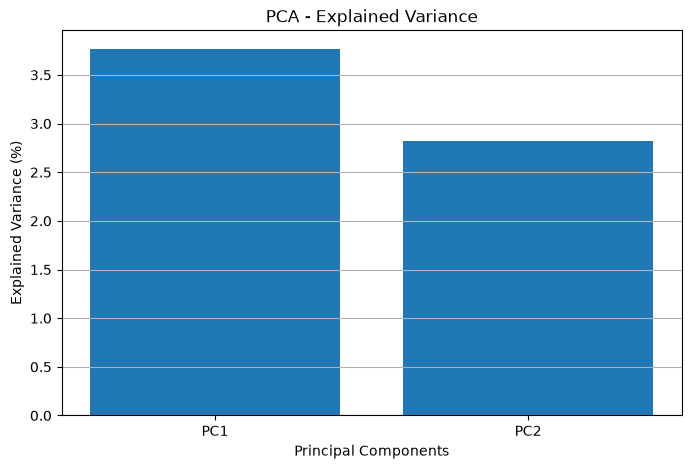

K-MEANS PCA DATASET
-------------------


,Principal_Component_1,Principal_Component_2,client_id,cluster
0,1.030792,0.635938,C0001,1
1,1.004531,0.665467,C0002,1
2,1.183238,-0.707172,C0003,1
3,1.008043,0.632330,C0004,1
4,0.998753,0.590030,C0005,1
5,1.050846,0.700728,C0006,1
6,-3.163662,-2.725392,C0007,1
7,1.034874,0.587911,C0008,1
8,1.110166,-0.833096,C0009,1
9,0.889398,-0.866399,C0010,1


Dataset Shape: (2000, 4)


In [45]:
# Step 1: Import libraries and load datasets
from sklearn.decomposition import PCA

print("PRINCIPAL COMPONENT ANALYSIS")
print("----------------------------")

scaled_features = pd.read_csv(
    project_path / "data" / "processed" / "scaled_features.csv"
)

kmeans_results = pd.read_csv(
    project_path / "data" / "processed" / "kmeans_cluster_results.csv"
)

hierarchical_results = pd.read_csv(
    project_path / "data" / "processed" / "hierarchical_cluster_results.csv"
)

client_ids = pd.read_csv(
    project_path / "data" / "processed" / "client_ids.csv"
)

print("Scaled Features Shape:", scaled_features.shape)
print("K-Means Results Shape:", kmeans_results.shape)
print("Hierarchical Results Shape:", hierarchical_results.shape)
# Step 2: Initialize PCA model
pca = PCA(n_components=2)

print("PCA MODEL INITIALIZED")
print("---------------------")
print("Number of Components:", pca.n_components)
# Step 3: Apply PCA transformation
pca_array = pca.fit_transform(scaled_features)

pca_features = pd.DataFrame(
    pca_array,
    columns=["Principal_Component_1", "Principal_Component_2"]
)

print("PCA TRANSFORMATION COMPLETED")
print("----------------------------")
print("Original Features:", scaled_features.shape[1])
print("Reduced Features:", pca_features.shape[1])
print("PCA Dataset Shape:", pca_features.shape)
# Step 4: Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("EXPLAINED VARIANCE RATIO")
print("------------------------")

for index, variance in enumerate(explained_variance):
    print(
        f"Principal Component {index + 1}: "
        f"{variance * 100:.2f}%"
    )

total_variance = explained_variance.sum() * 100

print(f"\nTotal Explained Variance: {total_variance:.2f}%")
# Step 5: Create explained variance table
variance_table = pd.DataFrame({
    "Principal Component": [
        "PC1",
        "PC2"
    ],
    "Explained Variance": explained_variance,
    "Explained Variance (%)": explained_variance * 100
})

display(variance_table.round(4))
# Step 6: Visualize explained variance
plt.figure(figsize=(8, 5))

plt.bar(
    ["PC1", "PC2"],
    explained_variance * 100
)

plt.title("PCA - Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.grid(axis="y")

plt.show()
# Step 7: Create K-Means PCA dataset
kmeans_pca = pca_features.copy()

kmeans_pca["client_id"] = client_ids["client_id"]
kmeans_pca["cluster"] = kmeans_results["cluster"]

print("K-MEANS PCA DATASET")
print("-------------------")

display(kmeans_pca.head(10))

print("Dataset Shape:", kmeans_pca.shape)


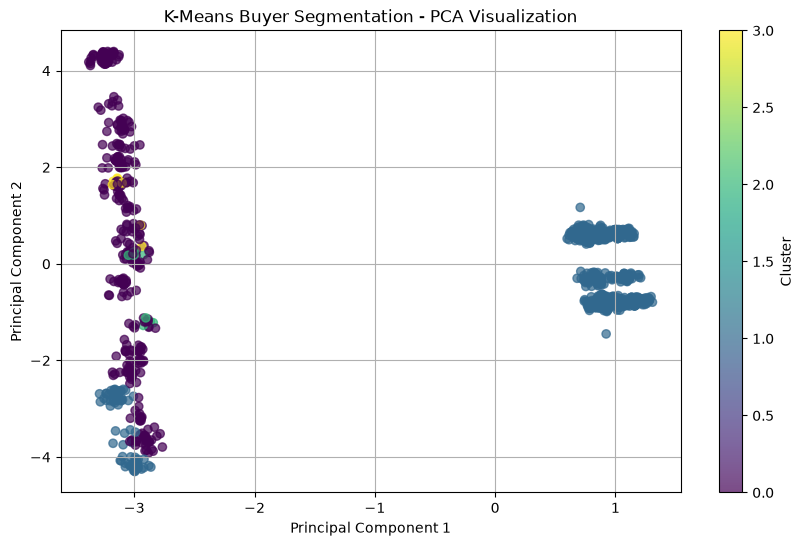

HIERARCHICAL PCA DATASET
------------------------


,Principal_Component_1,Principal_Component_2,client_id,cluster
0,1.030792,0.635938,C0001,1
1,1.004531,0.665467,C0002,1
2,1.183238,-0.707172,C0003,1
3,1.008043,0.632330,C0004,1
4,0.998753,0.590030,C0005,1
5,1.050846,0.700728,C0006,1
6,-3.163662,-2.725392,C0007,0
7,1.034874,0.587911,C0008,1
8,1.110166,-0.833096,C0009,1
9,0.889398,-0.866399,C0010,1


Dataset Shape: (2000, 4)


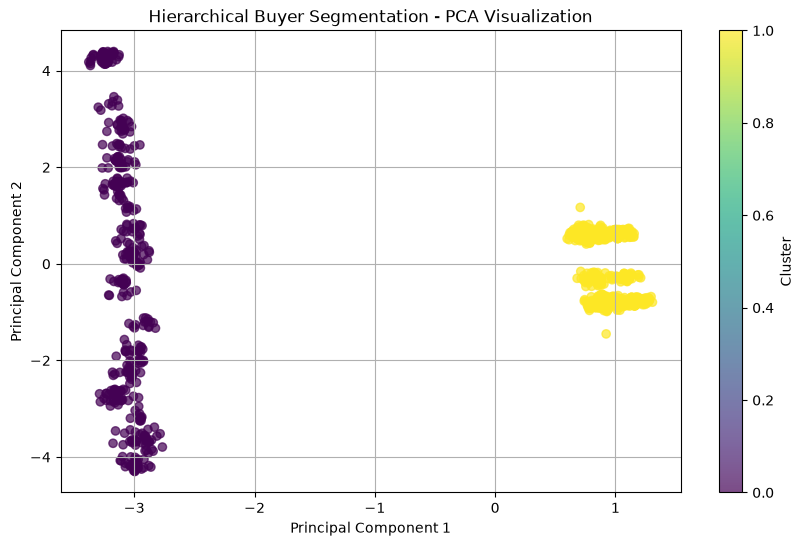

K-MEANS PCA CLUSTER DISTRIBUTION
--------------------------------


cluster
0     356
1    1623
2      10
3      11
Name: count, dtype: int64


HIERARCHICAL PCA CLUSTER DISTRIBUTION
------------------------------------


cluster
0     462
1    1538
Name: count, dtype: int64

PCA RESULTS SAVED SUCCESSFULLY!
1. kmeans_pca_results.csv
2. hierarchical_pca_results.csv
3. pca_explained_variance.csv
PCA FINAL VALIDATION
--------------------
Original Dataset Shape: (2000, 76)
PCA Dataset Shape: (2000, 2)
Missing PCA Values: 0
Duplicate Client IDs: 0
K-Means Cluster Count: 4
Hierarchical Cluster Count: 2
Explained Variance: 6.59 %

PCA ANALYSIS COMPLETED SUCCESSFULLY!


In [46]:
# Step 8: Visualize K-Means clusters using PCA
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    kmeans_pca["Principal_Component_1"],
    kmeans_pca["Principal_Component_2"],
    c=kmeans_pca["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("K-Means Buyer Segmentation - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(scatter, label="Cluster")
plt.grid(True)

plt.show()

# Step 9: Create Hierarchical PCA dataset
hierarchical_pca = pca_features.copy()

hierarchical_pca["client_id"] = client_ids["client_id"]

hierarchical_pca["cluster"] = (
    hierarchical_results["hierarchical_cluster"]
)

print("HIERARCHICAL PCA DATASET")
print("------------------------")

display(hierarchical_pca.head(10))

print("Dataset Shape:", hierarchical_pca.shape)

# Step 10: Visualize Hierarchical clusters using PCA
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    hierarchical_pca["Principal_Component_1"],
    hierarchical_pca["Principal_Component_2"],
    c=hierarchical_pca["cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.title("Hierarchical Buyer Segmentation - PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(scatter, label="Cluster")
plt.grid(True)

plt.show()
# Step 11: Compare PCA cluster distributions
print("K-MEANS PCA CLUSTER DISTRIBUTION")
print("--------------------------------")

display(
    kmeans_pca["cluster"].value_counts().sort_index()
)

print("\nHIERARCHICAL PCA CLUSTER DISTRIBUTION")
print("------------------------------------")

display(
    hierarchical_pca["cluster"].value_counts().sort_index()
)

# Step 12: Save PCA results
results_path = project_path / "data" / "processed"

kmeans_pca.to_csv(
    results_path / "kmeans_pca_results.csv",
    index=False
)

hierarchical_pca.to_csv(
    results_path / "hierarchical_pca_results.csv",
    index=False
)

variance_table.to_csv(
    results_path / "pca_explained_variance.csv",
    index=False
)

print("PCA RESULTS SAVED SUCCESSFULLY!")
print("1. kmeans_pca_results.csv")
print("2. hierarchical_pca_results.csv")
print("3. pca_explained_variance.csv")

# Step 13: Final PCA validation
print("PCA FINAL VALIDATION")
print("--------------------")

print("Original Dataset Shape:", scaled_features.shape)
print("PCA Dataset Shape:", pca_features.shape)

print(
    "Missing PCA Values:",
    pca_features.isnull().sum().sum()
)

print(
    "Duplicate Client IDs:",
    kmeans_pca["client_id"].duplicated().sum()
)

print(
    "K-Means Cluster Count:",
    kmeans_pca["cluster"].nunique()
)

print(
    "Hierarchical Cluster Count:",
    hierarchical_pca["cluster"].nunique()
)

print(
    "Explained Variance:",
    round(total_variance, 2), "%"
)

print("\nPCA ANALYSIS COMPLETED SUCCESSFULLY!")



### PART 16: Geographic Buyer Analysis

Analyzed buyer distribution by country and region. Examined how buyers from different geographical locations were distributed across clusters.

GEOGRAPHIC BUYER ANALYSIS
-------------------------
Clients Shape: (2000, 12)
K-Means Results Shape: (2000, 2)

Datasets Loaded Successfully!
GEOGRAPHIC DATASET
------------------
Dataset Shape: (2000, 13)

Missing Cluster Values: 0


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,cluster
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,Yes,Website,1
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website,1
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency,1
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website,1
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website,1
5,C0006,Individual,Yurem,Wright,03-06-1957,M,USA,California,Home,3,Yes,Website,1
6,C0007,Individual,Xavier,Faulkner,5/24/1947,M,Canada,Quebec,Investment,5,No,Website,1
7,C0008,Individual,Kayden,Olsen,10/17/1969,F,USA,California,Home,5,No,Website,1
8,C0009,Individual,Joaquin,Mullins,10-05-1975,M,USA,California,Investment,5,No,Agency,1
9,C0010,Individual,Nicolas,Navarro,6/17/1966,M,USA,Oregon,Investment,3,No,Agency,1


COUNTRY-WISE BUYER DISTRIBUTION
--------------------------------


,Country,Number of Buyers
0,USA,1538
1,UK,95
2,Canada,85
3,Germany,56
4,France,53
5,Belgium,43
6,Mexico,40
7,Australia,39
8,Russia,36
9,Denmark,15


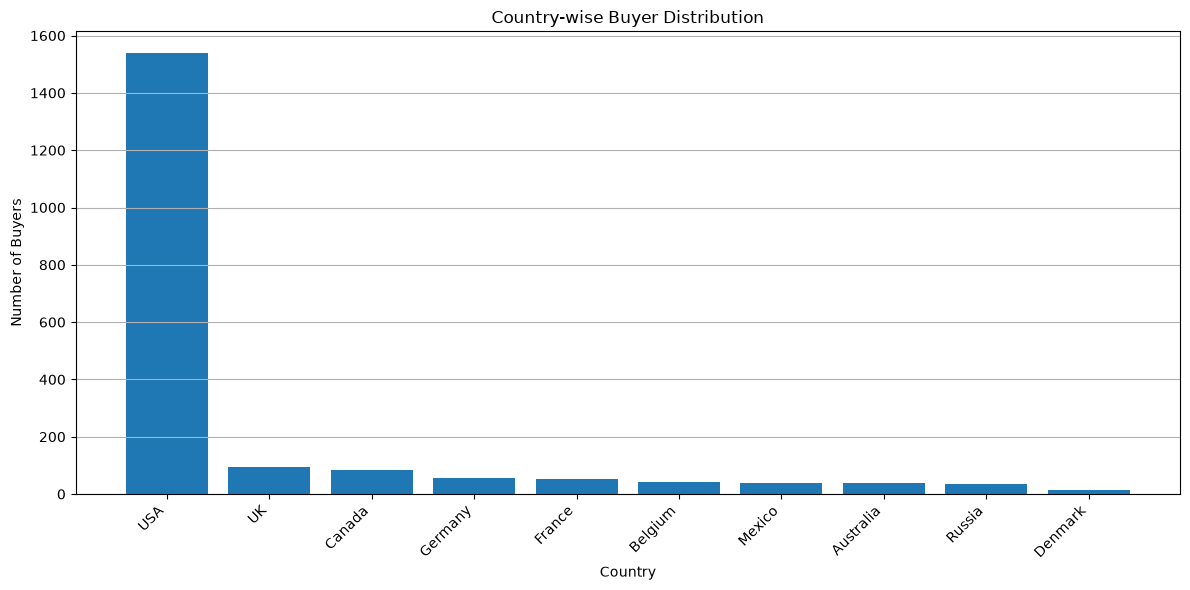

REGION-WISE BUYER DISTRIBUTION
------------------------------


,Region,Number of Buyers
0,California,633
1,Nevada,143
2,Colorado,118
3,Arizona,108
4,Oregon,96
5,Utah,87
6,Washington,73
7,Virginia,65
8,Texas,56
9,Florida,50


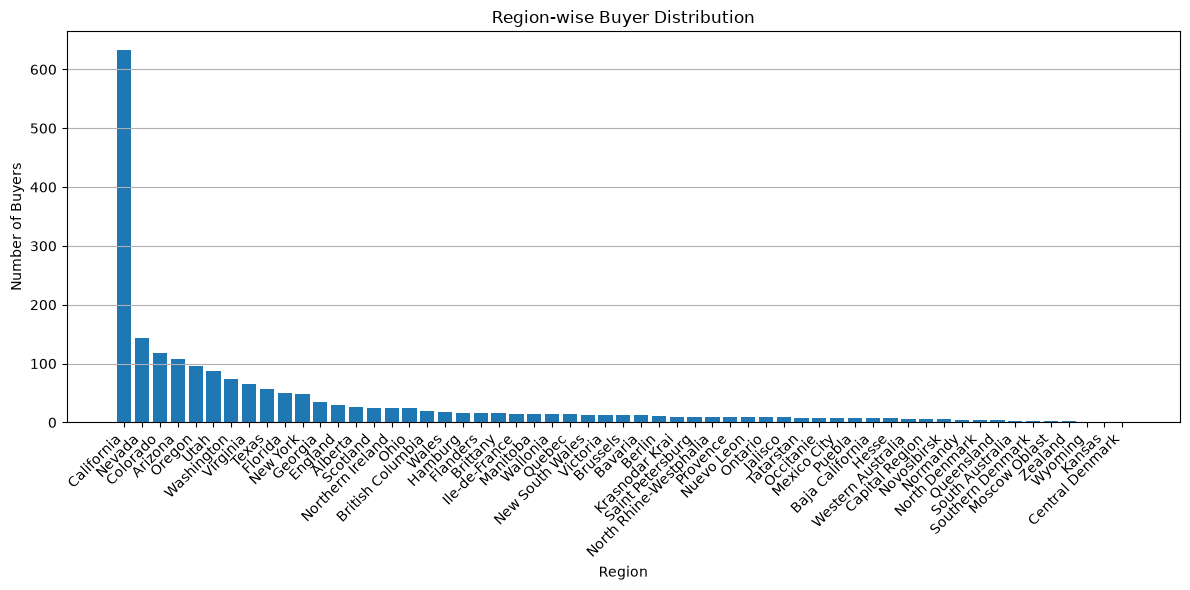

COUNTRY-WISE CLUSTER ANALYSIS
-----------------------------


cluster,0,1,2,3
country,,,,
Australia,39,0,0,0
Belgium,43,0,0,0
Canada,0,85,0,0
Denmark,15,0,0,0
France,53,0,0,0
Germany,45,0,0,11
Mexico,40,0,0,0
Russia,26,0,10,0
UK,95,0,0,0


REGION-WISE CLUSTER ANALYSIS
----------------------------


cluster,0,1,2,3
region,,,,
Alberta,0,27,0,0
Arizona,0,108,0,0
Baja California,7,0,0,0
Bavaria,12,0,0,0
Berlin,0,0,0,11
British Columbia,0,20,0,0
Brittany,16,0,0,0
Brussels,12,0,0,0
California,0,633,0,0


In [47]:
# Step 1: Load datasets
print("GEOGRAPHIC BUYER ANALYSIS")
print("-------------------------")

clients = pd.read_csv(
    project_path / "data" / "clients.csv"
)

kmeans_results = pd.read_csv(
    project_path / "data" / "processed" / "kmeans_cluster_results.csv"
)

print("Clients Shape:", clients.shape)
print("K-Means Results Shape:", kmeans_results.shape)

print("\nDatasets Loaded Successfully!")

# Step 2: Merge buyer and cluster information

geographic_data = clients.merge(
    kmeans_results[["client_id", "cluster"]],
    on="client_id",
    how="left"
)

print("GEOGRAPHIC DATASET")
print("------------------")

print("Dataset Shape:", geographic_data.shape)

print("\nMissing Cluster Values:",
      geographic_data["cluster"].isnull().sum())

display(geographic_data.head(10))
# Step 3: Country-wise buyer distribution
print("COUNTRY-WISE BUYER DISTRIBUTION")
print("--------------------------------")

country_distribution = (
    geographic_data["country"]
    .value_counts()
    .reset_index()
)

country_distribution.columns = [
    "Country",
    "Number of Buyers"
]

display(country_distribution)
# Step 4: Visualize country-wise buyers
plt.figure(figsize=(12, 6))

plt.bar(
    country_distribution["Country"].astype(str),
    country_distribution["Number of Buyers"]
)

plt.title("Country-wise Buyer Distribution")
plt.xlabel("Country")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()
# Step 5: Region-wise buyer distribution
print("REGION-WISE BUYER DISTRIBUTION")
print("------------------------------")

region_distribution = (
    geographic_data["region"]
    .value_counts()
    .reset_index()
)

region_distribution.columns = [
    "Region",
    "Number of Buyers"
]

display(region_distribution)
# Step 6: Visualize region-wise buyers
plt.figure(figsize=(12, 6))

plt.bar(
    region_distribution["Region"].astype(str),
    region_distribution["Number of Buyers"]
)

plt.title("Region-wise Buyer Distribution")
plt.xlabel("Region")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.tight_layout()
plt.show()
# Step 7: Country-wise cluster analysis
print("COUNTRY-WISE CLUSTER ANALYSIS")
print("-----------------------------")

country_cluster = pd.crosstab(
    geographic_data["country"],
    geographic_data["cluster"]
)

display(country_cluster)
# Step 8: Region-wise cluster analysis
print("REGION-WISE CLUSTER ANALYSIS")
print("----------------------------")

region_cluster = pd.crosstab(
    geographic_data["region"],
    geographic_data["cluster"]
)

display(region_cluster)

COUNTRY-WISE CLUSTER PERCENTAGES
--------------------------------


cluster,0,1,2,3
country,,,,
Australia,100.00,0.0,0.00,0.00
Belgium,100.00,0.0,0.00,0.00
Canada,0.00,100.0,0.00,0.00
Denmark,100.00,0.0,0.00,0.00
France,100.00,0.0,0.00,0.00
Germany,80.36,0.0,0.00,19.64
Mexico,100.00,0.0,0.00,0.00
Russia,72.22,0.0,27.78,0.00
UK,100.00,0.0,0.00,0.00


REGION-WISE CLUSTER PERCENTAGES
-------------------------------


cluster,0,1,2,3
region,,,,
Alberta,0.0,100.0,0.0,0.0
Arizona,0.0,100.0,0.0,0.0
Baja California,100.0,0.0,0.0,0.0
Bavaria,100.0,0.0,0.0,0.0
Berlin,0.0,0.0,0.0,100.0
British Columbia,0.0,100.0,0.0,0.0
Brittany,100.0,0.0,0.0,0.0
Brussels,100.0,0.0,0.0,0.0
California,0.0,100.0,0.0,0.0


<Figure size 1200x600 with 0 Axes>

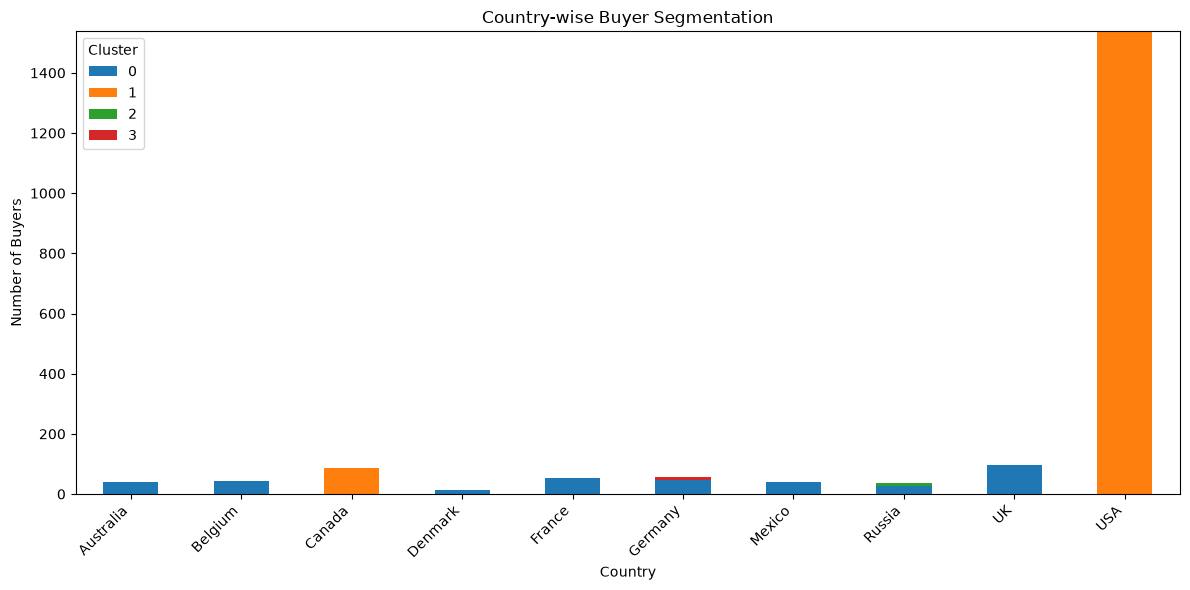

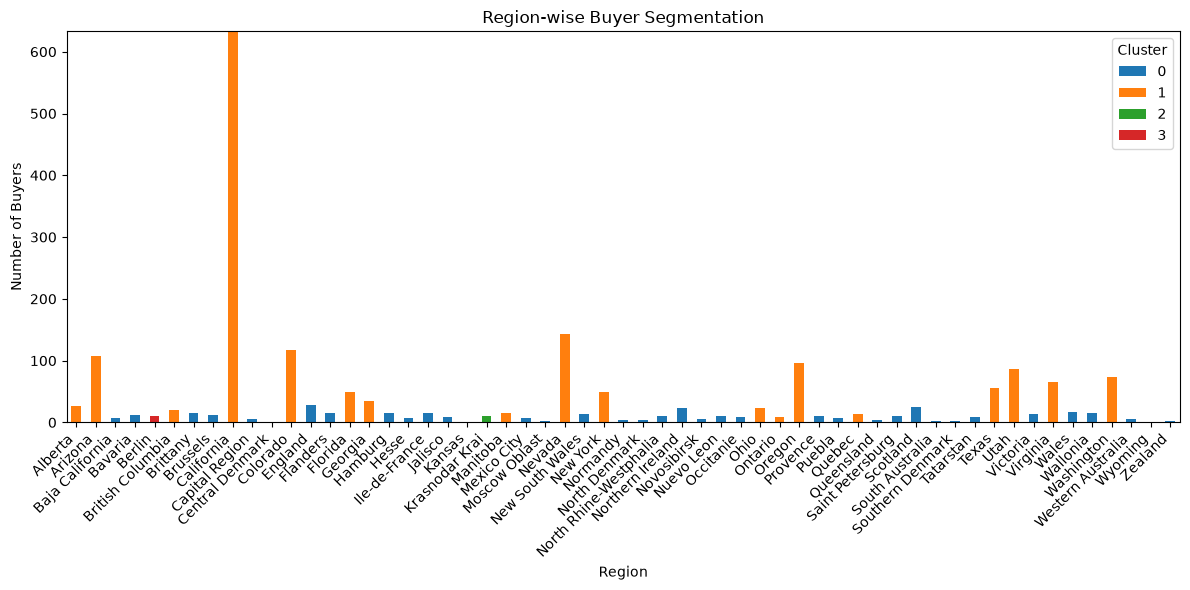

TOP 5 COUNTRIES BY BUYER COUNT
------------------------------


,Country,Number of Buyers
0,USA,1538
1,UK,95
2,Canada,85
3,Germany,56
4,France,53



TOP 5 REGIONS BY BUYER COUNT
----------------------------


,Region,Number of Buyers
0,California,633
1,Nevada,143
2,Colorado,118
3,Arizona,108
4,Oregon,96


GEOGRAPHIC ANALYSIS FILES SAVED SUCCESSFULLY!
1. country_buyer_distribution.csv
2. region_buyer_distribution.csv
3. country_cluster_analysis.csv
4. region_cluster_analysis.csv
5. country_cluster_percentage.csv
6. region_cluster_percentage.csv
GEOGRAPHIC ANALYSIS VALIDATION
------------------------------
Total Buyers: 2000
Unique Countries: 10
Unique Regions: 57
Missing Country Values: 0
Missing Region Values: 0
Missing Cluster Values: 0
Duplicate Client IDs: 0

GEOGRAPHIC BUYER ANALYSIS COMPLETED SUCCESSFULLY!


In [48]:
# Step 9: Calculate country-wise cluster percentages
print("COUNTRY-WISE CLUSTER PERCENTAGES")
print("--------------------------------")

country_cluster_percentage = pd.crosstab(
    geographic_data["country"],
    geographic_data["cluster"],
    normalize="index"
) * 100

display(country_cluster_percentage.round(2))
# Step 10: Calculate region-wise cluster percentages
print("REGION-WISE CLUSTER PERCENTAGES")
print("-------------------------------")

region_cluster_percentage = pd.crosstab(
    geographic_data["region"],
    geographic_data["cluster"],
    normalize="index"
) * 100

display(region_cluster_percentage.round(2))
# Step 11: Visualize country-wise cluster distribution
plt.figure(figsize=(12, 6))

country_cluster.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Country-wise Buyer Segmentation")
plt.xlabel("Country")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()

plt.show()
# Step 12: Visualize region-wise cluster distribution
region_cluster.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Region-wise Buyer Segmentation")
plt.xlabel("Region")
plt.ylabel("Number of Buyers")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()

plt.show()
# Step 13: Identify top countries and regions
print("TOP 5 COUNTRIES BY BUYER COUNT")
print("------------------------------")

display(country_distribution.head(5))

print("\nTOP 5 REGIONS BY BUYER COUNT")
print("----------------------------")

display(region_distribution.head(5))
# Step 14: Save geographic analysis results
results_path = project_path / "data" / "processed"

country_distribution.to_csv(
    results_path / "country_buyer_distribution.csv",
    index=False
)

region_distribution.to_csv(
    results_path / "region_buyer_distribution.csv",
    index=False
)

country_cluster.to_csv(
    results_path / "country_cluster_analysis.csv"
)

region_cluster.to_csv(
    results_path / "region_cluster_analysis.csv"
)

country_cluster_percentage.to_csv(
    results_path / "country_cluster_percentage.csv"
)

region_cluster_percentage.to_csv(
    results_path / "region_cluster_percentage.csv"
)

print("GEOGRAPHIC ANALYSIS FILES SAVED SUCCESSFULLY!")

print("1. country_buyer_distribution.csv")
print("2. region_buyer_distribution.csv")
print("3. country_cluster_analysis.csv")
print("4. region_cluster_analysis.csv")
print("5. country_cluster_percentage.csv")
print("6. region_cluster_percentage.csv")

# Step 15: Final validation
print("GEOGRAPHIC ANALYSIS VALIDATION")
print("------------------------------")

print("Total Buyers:", len(geographic_data))

print(
    "Unique Countries:",
    geographic_data["country"].nunique()
)

print(
    "Unique Regions:",
    geographic_data["region"].nunique()
)

print(
    "Missing Country Values:",
    geographic_data["country"].isnull().sum()
)

print(
    "Missing Region Values:",
    geographic_data["region"].isnull().sum()
)

print(
    "Missing Cluster Values:",
    geographic_data["cluster"].isnull().sum()
)

print(
    "Duplicate Client IDs:",
    geographic_data["client_id"].duplicated().sum()
)

print("\nGEOGRAPHIC BUYER ANALYSIS COMPLETED SUCCESSFULLY!")

### PART 17: Property and Buyer Analysis
Connected buyer information with property transaction records using client references. Analyzed sale prices, floor areas and property unit categories.

PROPERTY AND BUYER ANALYSIS
---------------------------
Clients Shape: (2000, 12)
Properties Shape: (10000, 9)
K-Means Results Shape: (2000, 2)
PROPERTY DATA CLEANING COMPLETED
--------------------------------
Properties Shape: (10000, 9)
Missing Client References: 2695
CLIENT DATA PREPARED
--------------------
Total Clients: 2000
Unique Client IDs: 2000
CLIENT-PROPERTY MATCHING ANALYSIS
---------------------------------
Total Property Records: 10000
Properties with Client Reference: 7305
Matched Property Records: 7305
Unmatched Property Records: 0
Missing Client References: 2695
CLIENT-PROPERTY MERGE COMPLETED
--------------------------------
Linked Dataset Shape: (7305, 21)


,listing_id,tower_number,transaction_date,unit_category,unit_number,floor_area_sqft,sale_price,listing_status,client_ref,client_id,...,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel
0,1012,1,2024-01-01,Apartment,12,1160.36,300385.62,Sold,C0027,C0027,...,Grant,Weber,09-08-1968,M,USA,California,Home,5,Yes,Website
1,1015,1,2024-01-01,Apartment,15,782.25,208930.81,Sold,C0097,C0097,...,Franklin,Mack,6/18/1943,M,USA,Virginia,Home,5,Yes,Website
2,1021,1,2024-01-01,Apartment,21,756.21,218585.92,Sold,C0113,C0113,...,Arthur,Bray,7/14/1949,M,USA,Utah,Investment,4,No,Agency
3,1030,1,2024-01-01,Apartment,30,743.09,246172.68,Sold,C0141,C0141,...,Madalyn,Mercer,6/21/1986,F,USA,California,Home,5,No,Website
4,2016,2,2024-01-01,Apartment,16,701.66,212265.67,Sold,C0146,C0146,...,Hazel,Ayers,02-01-1963,M,USA,Colorado,Home,2,No,Website
5,2018,2,2024-01-01,Apartment,18,927.83,275394.25,Sold,C0023,C0023,...,Cole,Taylor,12-06-1958,M,USA,California,Home,3,Yes,Website
6,2029,2,2024-01-01,Apartment,29,1109.25,310223.29,Sold,C0040,C0040,...,Conner,Huff,3/22/1975,M,USA,Nevada,Home,5,No,Website
7,3006,3,2024-01-01,Apartment,6,1132.06,356506.37,Sold,C0007,C0007,...,Xavier,Faulkner,5/24/1947,M,Canada,Quebec,Investment,5,No,Website
8,3026,3,2024-01-01,Apartment,26,670.89,212520.83,Sold,C0082,C0082,...,Kaitlin,Owen,12/26/1981,F,USA,Virginia,Investment,5,No,Client
9,3031,3,2024-01-01,Apartment,31,1596.35,407214.29,Sold,C0038,C0038,...,Janelle,Espinoza,12/25/1974,F,USA,California,Investment,4,No,Client


PROPERTY COUNT PER BUYER
------------------------


,client_id,property_records,unique_listings
0,C0001,4,4
1,C0002,5,5
2,C0003,5,5
3,C0004,6,6
4,C0005,13,13
5,C0006,5,5
6,C0007,11,11
7,C0008,5,5
8,C0009,5,5
9,C0010,5,5


Buyers with Linked Properties: 2000
BUYER-WISE PROPERTY STATISTICS
------------------------------


,client_id,property_records,unique_listings,average_sale_price,median_sale_price,average_floor_area,first_transaction,last_transaction
0,C0001,4,4,311691.180000,287449.205,983.885000,2024-01-10,2025-01-12
1,C0002,5,5,368219.186000,336892.390,1187.942000,2024-01-01,2025-01-12
2,C0003,5,5,332291.518000,260144.680,1058.110000,2024-01-07,2025-01-10
3,C0004,6,6,268043.918333,212718.115,937.103333,2024-01-02,2025-01-08
4,C0005,13,13,281029.644615,229412.620,927.296154,2024-01-02,2025-01-05
5,C0006,5,5,302826.212000,294158.670,989.590000,2024-01-01,2025-01-11
6,C0007,11,11,295558.893636,247739.440,995.693636,2024-01-01,2025-01-12
7,C0008,5,5,295346.082000,234283.570,1031.106000,2024-01-03,2025-01-03
8,C0009,5,5,364166.470000,396973.830,1305.644000,2024-01-12,2025-01-05
9,C0010,5,5,346486.800000,340333.170,1140.206000,2024-01-03,2025-01-09


Buyer Property Analysis Shape: (2000, 8)
PROPERTY SALE PRICE ANALYSIS
----------------------------
count      7305.000000
mean     345072.000115
std      132053.768307
min       97402.800000
25%      232448.630000
50%      330997.320000
75%      451237.670000
max      736652.270000
Name: sale_price, dtype: float64


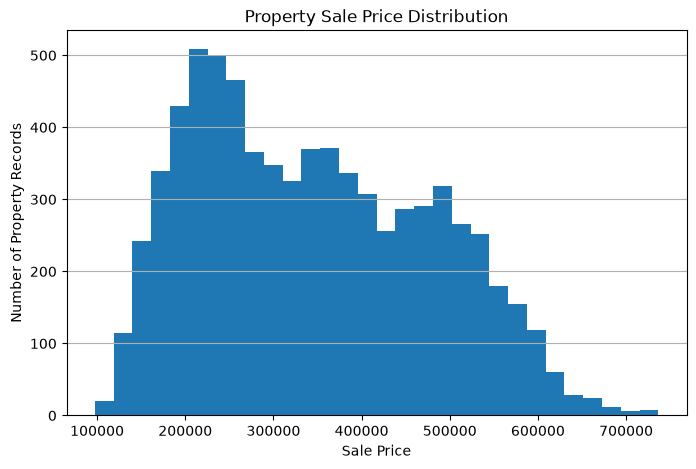

In [49]:
# Step 1: Load datasets
print("PROPERTY AND BUYER ANALYSIS")
print("---------------------------")

clients = pd.read_csv(
    project_path / "data" / "clients.csv"
)

properties = pd.read_csv(
    project_path / "data" / "properties.csv"
)

kmeans_results = pd.read_csv(
    project_path / "data" / "processed" / "kmeans_cluster_results.csv"
)

print("Clients Shape:", clients.shape)
print("Properties Shape:", properties.shape)
print("K-Means Results Shape:", kmeans_results.shape)
# Step 2: Clean property data
properties_clean = properties.copy()

properties_clean["client_ref"] = (
    properties_clean["client_ref"]
    .astype("string")
    .str.strip()
)

properties_clean["sale_price"] = pd.to_numeric(
    properties_clean["sale_price"]
    .astype(str)
    .str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

properties_clean["floor_area_sqft"] = pd.to_numeric(
    properties_clean["floor_area_sqft"],
    errors="coerce"
)

properties_clean["transaction_date"] = pd.to_datetime(
    properties_clean["transaction_date"],
    errors="coerce",
    dayfirst=True
)

properties_clean.loc[
    properties_clean["client_ref"].eq(""),
    "client_ref"
] = pd.NA

print("PROPERTY DATA CLEANING COMPLETED")
print("--------------------------------")
print("Properties Shape:", properties_clean.shape)
print("Missing Client References:",
      properties_clean["client_ref"].isna().sum())
# Step 3: Prepare client IDs
clients_clean = clients.copy()

clients_clean["client_id"] = (
    clients_clean["client_id"]
    .astype("string")
    .str.strip()
)

print("CLIENT DATA PREPARED")
print("--------------------")
print("Total Clients:", len(clients_clean))
print("Unique Client IDs:", clients_clean["client_id"].nunique())
# Step 4: Check client-property matching
print("CLIENT-PROPERTY MATCHING ANALYSIS")
print("---------------------------------")

valid_properties = properties_clean[
    properties_clean["client_ref"].notna()
].copy()

matched_properties = valid_properties[
    valid_properties["client_ref"].isin(
        clients_clean["client_id"]
    )
]

unmatched_properties = valid_properties[
    ~valid_properties["client_ref"].isin(
        clients_clean["client_id"]
    )
]

print("Total Property Records:", len(properties_clean))
print("Properties with Client Reference:", len(valid_properties))
print("Matched Property Records:", len(matched_properties))
print("Unmatched Property Records:", len(unmatched_properties))
print("Missing Client References:",
      properties_clean["client_ref"].isna().sum())

# Step 5: Merge client and property records
linked_properties = matched_properties.merge(
    clients_clean,
    left_on="client_ref",
    right_on="client_id",
    how="inner",
    validate="many_to_one"
)

print("CLIENT-PROPERTY MERGE COMPLETED")
print("--------------------------------")
print("Linked Dataset Shape:", linked_properties.shape)

display(linked_properties.head(10))
# Step 6: Analyze property records per buyer
print("PROPERTY COUNT PER BUYER")
print("------------------------")

property_count = (
    linked_properties.groupby("client_id")
    .agg(
        property_records=("listing_id", "size"),
        unique_listings=("listing_id", "nunique")
    )
    .reset_index()
)

display(property_count.head(10))

print("Buyers with Linked Properties:", len(property_count))
# Step 7: Calculate buyer-wise property statistics
print("BUYER-WISE PROPERTY STATISTICS")
print("------------------------------")

buyer_property_analysis = (
    linked_properties.groupby("client_id")
    .agg(
        property_records=("listing_id", "size"),
        unique_listings=("listing_id", "nunique"),
        average_sale_price=("sale_price", "mean"),
        median_sale_price=("sale_price", "median"),
        average_floor_area=("floor_area_sqft", "mean"),
        first_transaction=("transaction_date", "min"),
        last_transaction=("transaction_date", "max")
    )
    .reset_index()
)

display(buyer_property_analysis.head(10))

print("Buyer Property Analysis Shape:",
      buyer_property_analysis.shape)
# Step 8: Analyze property prices
print("PROPERTY SALE PRICE ANALYSIS")
print("----------------------------")

print(
    linked_properties["sale_price"].describe()
)

plt.figure(figsize=(8, 5))

plt.hist(
    linked_properties["sale_price"].dropna(),
    bins=30
)

plt.title("Property Sale Price Distribution")
plt.xlabel("Sale Price")
plt.ylabel("Number of Property Records")
plt.grid(axis="y")

plt.show()

PROPERTY SIZE ANALYSIS
----------------------
count    7305.000000
mean     1141.147838
std       419.241645
min       410.710000
25%       782.150000
50%      1110.880000
75%      1501.640000
max      1957.160000
Name: floor_area_sqft, dtype: float64


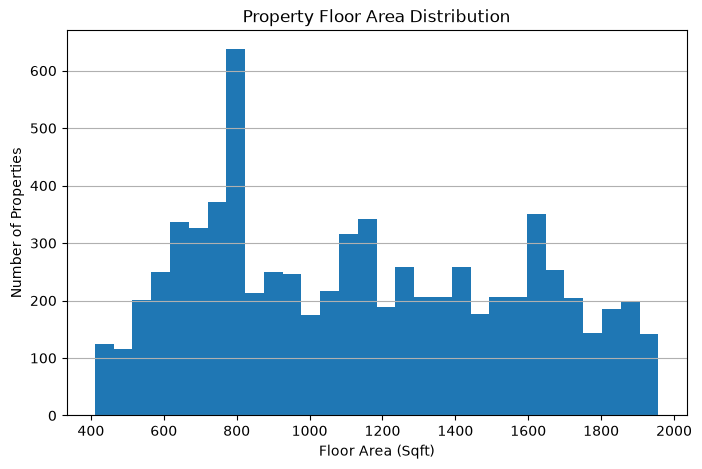

PROPERTY UNIT CATEGORY ANALYSIS
--------------------------------


unit_category
Apartment    6225
Office       1080
Name: count, dtype: int64

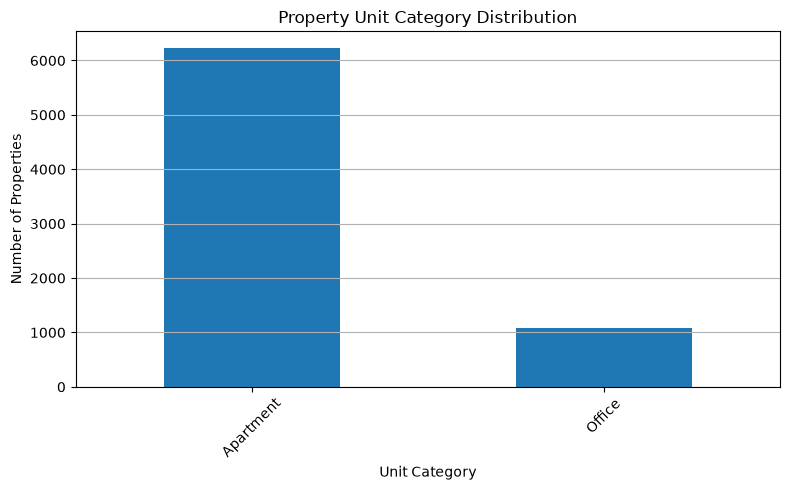

CLUSTER-WISE PROPERTY ANALYSIS
------------------------------


,cluster,buyers,property_records,average_sale_price,average_floor_area
0,0,356,1278,344761.25,1144.59
1,1,1623,5956,345141.60,1140.59
2,2,10,35,344813.14,1124.56
3,3,11,36,344839.69,1127.25


PROPERTY ANALYSIS FILES SAVED SUCCESSFULLY!
1. buyer_property_analysis.csv
2. clustered_property_data.csv
3. cluster_property_analysis.csv
4. property_unit_category_analysis.csv
PROPERTY AND BUYER ANALYSIS VALIDATION
--------------------------------------
Total Clients: 2000
Total Properties: 10000
Linked Property Records: 7305
Unmatched Property Records: 0
Missing Client References: 2695
Duplicate Client IDs: 0
Missing Cluster Values: 0

PROPERTY AND BUYER ANALYSIS COMPLETED!


In [50]:
# Step 9: Analyze property sizes
print("PROPERTY SIZE ANALYSIS")
print("----------------------")

print(
    linked_properties["floor_area_sqft"].describe()
)

plt.figure(figsize=(8, 5))

plt.hist(
    linked_properties["floor_area_sqft"].dropna(),
    bins=30
)

plt.title("Property Floor Area Distribution")
plt.xlabel("Floor Area (Sqft)")
plt.ylabel("Number of Properties")
plt.grid(axis="y")

plt.show()
# Step 10: Analyze property categories
print("PROPERTY UNIT CATEGORY ANALYSIS")
print("--------------------------------")

unit_category_analysis = (
    linked_properties["unit_category"]
    .value_counts()
)

display(unit_category_analysis)

unit_category_analysis.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Property Unit Category Distribution")
plt.xlabel("Unit Category")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.tight_layout()
plt.show()
# Step 11: Analyze property information by K-Means cluster
print("CLUSTER-WISE PROPERTY ANALYSIS")
print("------------------------------")

clustered_property_data = linked_properties.merge(
    kmeans_results[["client_id", "cluster"]],
    on="client_id",
    how="left",
    validate="many_to_one"
)

cluster_property_analysis = (
    clustered_property_data.groupby("cluster")
    .agg(
        buyers=("client_id", "nunique"),
        property_records=("listing_id", "size"),
        average_sale_price=("sale_price", "mean"),
        average_floor_area=("floor_area_sqft", "mean")
    )
    .reset_index()
)

display(cluster_property_analysis.round(2))
# Step 12: Save property and buyer analysis resultsresults_path = project_path / "data" / "processed"

buyer_property_analysis.to_csv(
    results_path / "buyer_property_analysis.csv",
    index=False
)

clustered_property_data.to_csv(
    results_path / "clustered_property_data.csv",
    index=False
)

cluster_property_analysis.to_csv(
    results_path / "cluster_property_analysis.csv",
    index=False
)

unit_category_analysis.to_csv(
    results_path / "property_unit_category_analysis.csv"
)

print("PROPERTY ANALYSIS FILES SAVED SUCCESSFULLY!")

print("1. buyer_property_analysis.csv")
print("2. clustered_property_data.csv")
print("3. cluster_property_analysis.csv")
print("4. property_unit_category_analysis.csv")
# Step 13: Final validation
print("PROPERTY AND BUYER ANALYSIS VALIDATION")
print("--------------------------------------")

print("Total Clients:", len(clients_clean))

print("Total Properties:", len(properties_clean))

print("Linked Property Records:", len(linked_properties))

print("Unmatched Property Records:", len(unmatched_properties))

print(
    "Missing Client References:",
    properties_clean["client_ref"].isna().sum()
)

print(
    "Duplicate Client IDs:",
    clients_clean["client_id"].duplicated().sum()
)

print(
    "Missing Cluster Values:",
    clustered_property_data["cluster"].isna().sum()
)

print("\nPROPERTY AND BUYER ANALYSIS COMPLETED!")

### PART 18: Final Cluster Interpretation
Combined buyer segmentation and property analysis results. Studied cluster characteristics and generated final buyer segment insights.

In [51]:
# Step 1: Prepare the final buyer dataset
print("FINAL BUYER CLUSTER ANALYSIS")
print("----------------------------")

final_buyer_data = clustered_clients.merge(
    buyer_property_analysis,
    on="client_id",
    how="left"
)

print("Final Dataset Shape:", final_buyer_data.shape)
display(final_buyer_data.head())
# Step 2: Cluster distribution
print("BUYER DISTRIBUTION BY CLUSTER")
print("------------------------------")

cluster_distribution = (
    final_buyer_data["cluster"]
    .value_counts()
    .sort_index()
)

display(cluster_distribution)
# Step 3: Buyer type analysis
print("BUYER TYPE BY CLUSTER")
print("---------------------")

display(
    pd.crosstab(
        final_buyer_data["cluster"],
        final_buyer_data["client_type"],
        normalize="index"
    ).mul(100).round(2)
)
# Step 4: Acquisition purpose analysis
print("ACQUISITION PURPOSE BY CLUSTER")
print("------------------------------")

display(
    pd.crosstab(
        final_buyer_data["cluster"],
        final_buyer_data["acquisition_purpose"],
        normalize="index"
    ).mul(100).round(2)
)
# Step 5: Loan behavior analysis
print("LOAN BEHAVIOR BY CLUSTER")
print("------------------------")

display(
    pd.crosstab(
        final_buyer_data["cluster"],
        final_buyer_data["loan_applied"],
        normalize="index"
    ).mul(100).round(2)
)
# Step 6: Property ownership analysis
print("PROPERTY PERFORMANCE BY CLUSTER")
print("--------------------------------")

cluster_property_profile = final_buyer_data.groupby(
    "cluster"
).agg(
    buyers=("client_id", "count"),
    property_records=("property_records", "sum"),
    average_sale_price=("average_sale_price", "mean"),
    average_floor_area=("average_floor_area", "mean"),
    average_satisfaction=("satisfaction_score", "mean")
)

display(cluster_property_profile.round(2))
# Step 7: Save final cluster interpretation
reports_path = project_path / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

cluster_property_profile.to_csv(
    reports_path / "final_cluster_interpretation.csv"
)

print("FINAL CLUSTER INTERPRETATION SAVED!")
print("File: final_cluster_interpretation.csv")
# Step 8: Final validation
print("FINAL CLUSTER VALIDATION")
print("------------------------")

print("Total Buyers:", len(final_buyer_data))
print("Unique Client IDs:", final_buyer_data["client_id"].nunique())
print("Missing Cluster Values:", final_buyer_data["cluster"].isna().sum())
print("Missing Property Records:", final_buyer_data["property_records"].isna().sum())
print("Number of Clusters:", final_buyer_data["cluster"].nunique())

print("\nPART 18 COMPLETED!")

FINAL BUYER CLUSTER ANALYSIS
----------------------------
Final Dataset Shape: (2000, 20)


,client_id,client_type,first_name,last_name,date_of_birth,gender,country,region,acquisition_purpose,satisfaction_score,loan_applied,referral_channel,cluster,property_records,unique_listings,average_sale_price,median_sale_price,average_floor_area,first_transaction,last_transaction
0,C0001,Individual,Kareem,Liu,05-11-1968,F,USA,California,Home,4,Yes,Website,1,4,4,311691.180000,287449.205,983.885000,2024-01-10,2025-01-12
1,C0002,Individual,Trystan,Oconnor,11/26/1962,M,USA,California,Home,1,No,Website,1,5,5,368219.186000,336892.390,1187.942000,2024-01-01,2025-01-12
2,C0003,Individual,Kale,Gay,04-07-1959,M,USA,California,Home,4,Yes,Agency,1,5,5,332291.518000,260144.680,1058.110000,2024-01-07,2025-01-10
3,C0004,Individual,Russell,Gross,11/25/1959,M,USA,California,Home,5,No,Website,1,6,6,268043.918333,212718.115,937.103333,2024-01-02,2025-01-08
4,C0005,Company,Marleez,Co,2/28/1976,M,USA,California,Investment,5,No,Website,1,13,13,281029.644615,229412.620,927.296154,2024-01-02,2025-01-05


BUYER DISTRIBUTION BY CLUSTER
------------------------------


cluster
0     356
1    1623
2      10
3      11
Name: count, dtype: int64

BUYER TYPE BY CLUSTER
---------------------


client_type,Company,Individual
cluster,,
0,5.06,94.94
1,5.11,94.89
2,0.00,100.00
3,18.18,81.82


... (3 outputs left out)

loan_applied,No,Yes
cluster,,
0,62.08,37.92
1,63.22,36.78
2,90.00,10.00
3,72.73,27.27


PROPERTY PERFORMANCE BY CLUSTER
--------------------------------


,buyers,property_records,average_sale_price,average_floor_area,average_satisfaction
cluster,,,,,
0,356,1278,346243.22,1149.19,3.00
1,1623,5956,347307.96,1147.40,3.04
2,10,35,340890.14,1114.04,2.00
3,11,36,347964.72,1133.55,3.27


FINAL CLUSTER INTERPRETATION SAVED!
File: final_cluster_interpretation.csv
FINAL CLUSTER VALIDATION
------------------------
Total Buyers: 2000
Unique Client IDs: 2000
Missing Cluster Values: 0
Missing Property Records: 0
Number of Clusters: 4

PART 18 COMPLETED!


### PART 19: Final Project Data Saving

Saved final buyer segmentation, cluster summary, cluster distribution and project validation files. Completed the final data preparation and validation process.

In [52]:
# Step 1: Create output folder
final_output_path = project_path / "data" / "final"
final_output_path.mkdir(parents=True, exist_ok=True)

print("Final output folder created successfully!")
# Step 2: Save final buyer dataset
final_buyer_data.to_csv(
    final_output_path / "final_buyer_segmentation.csv",
    index=False
)

print("Final buyer segmentation saved!")
# Step 3: Save cluster interpretation
cluster_property_profile.to_csv(
    final_output_path / "final_cluster_summary.csv"
)

print("Final cluster summary saved!")
# Step 4: Save cluster distribution
cluster_distribution.to_csv(
    final_output_path / "final_cluster_distribution.csv",
    header=["buyer_count"]
)

print("Final cluster distribution saved!")
# Step 5: Save final project validation
validation_summary = pd.DataFrame({
    "Metric": [
        "Total Buyers",
        "Unique Client IDs",
        "Total Clusters",
        "Missing Cluster Values",
        "Missing Property Records",
        "Total Linked Property Records"
    ],
    "Value": [
        len(final_buyer_data),
        final_buyer_data["client_id"].nunique(),
        final_buyer_data["cluster"].nunique(),
        final_buyer_data["cluster"].isna().sum(),
        final_buyer_data["property_records"].isna().sum(),
        final_buyer_data["property_records"].sum()
    ]
})

display(validation_summary)

validation_summary.to_csv(
    final_output_path / "project_validation.csv",
    index=False
)
# Step 6: Final confirmation

print("FINAL PROJECT FILES")
print("-------------------")

for file in sorted(final_output_path.iterdir()):
    print(file.name)

print("\nPART 19 COMPLETED SUCCESSFULLY!")

Final output folder created successfully!
Final buyer segmentation saved!
Final cluster summary saved!
Final cluster distribution saved!


,Metric,Value
0,Total Buyers,2000
1,Unique Client IDs,2000
2,Total Clusters,4
3,Missing Cluster Values,0
4,Missing Property Records,0
5,Total Linked Property Records,7305


FINAL PROJECT FILES
-------------------
final_buyer_segmentation.csv
final_cluster_distribution.csv
final_cluster_summary.csv
project_validation.csv

PART 19 COMPLETED SUCCESSFULLY!
